## **Distributed Lag Non-Linear Model (Negative Binomial)**
**AIM**: 
To identify the lag effect between influenza case counts and meteorological data

**Justification of using DLNM**
1. Non-linear relationship is observed between the exposures (meteorological variables) and outcomes (count for influenza cases)
2. We want to identify the lag effect between exposure and outcome → can be done by cross basis matrix
3. Controls other variables

**Workflow**
1. Preparation stage
    - Determine maximum lag period
    - Spot out confounders
    - Determine the distribution family used
    - Decide smoother types
2. Tuning CrossBasis hyperparameters 
    1. Degree of the spline for the lag dimension
    2. Degrees of freedom (df) of the spline for the lag dimension
    3. Degree of the spline for the exposure dimension
    4. Degrees of freedom (df) of the spline for the exposure dimension
3. Tuning smoothers hyperparameters  
    1. Degrees of freedom (df) for each of the smoothers 
    2. Smoothing penalities 
4. Tuning Negative Binomial dispersion parameter

**Hyperparameter tuning**
1. degree and degrees of freedom for CrossBasis
    - BIC value
2. degrees of freedom for smoothers
    - BIC value
3. Penalty weight for smoothers
    - By using the `select_penweight()` function provided by `statsmodels`
        - Use `criterion=gcv`, and `method=nm`
    - By using the `select_penweight__kfold()` function provided by `statsmodels`
4. Dispersion parameter 
    - $\chi2$ $\div$ Deviance

**Justification for using Negative Binmoial as the distribution family**
1. The independent variable is a count → Poisson / Quasi-Poisson / Negative Binomial / Tweedie 
2. The independent variable is a discrete number → Poisson / Quasi-Poisson / Negative Binomial 
3. Extreme overpiserion (variance is a lot larger than mean) exist → Negative Binomial

**Confounders variables (smoothers and linear predictors)**

|Variable name|Role||
|---|---|---|
|`pandemic_flag`|Linear predictor|
|`sars_flag`|Linear predictor|
|`school_flag`|Linear predictor|
|`population`|Offset|
|`time`|smoother (B-spline)|
|`ContainmentHealthIndex_Average`|smoother (B-spline)|
|`Week`|smoother (Cyclic Cubic Spine)|

**Result diagnostics metrics**
|Metic Name|Description|Perferred value|
|---|---|---|
|Akaike Information Criterion (AIC)|shows relative predictive fit|lower value|
|Bayesian Information Criterion (BIC)|stronger penalty when high complexity, often preferred than AIC|lower value|
|$\chi2$/ deviance|measures the appropiacy of the dispersion parameter|closer to 1|
|Effective degree of freedom||positive and close to 1|
|Pseudo R-square|the grometric mean squared improvement per observation over a baseline model|higher|


---

In [2]:
# Import necessary libraries

# Basics
import itertools
import warnings
import io
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# DLNM helpers 
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from dlnm import plot_crosspred, cb_pen

# statsmodels for GLMGam
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines, GenericSmoothers
from statsmodels.tsa.stattools import acf


---
### **Functions**
#### 1. Constructions for CrossBasis matrix, smoothers, and the model

In [3]:
# CrossBasis matrix construction
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    # Input the processed data, exposure variable list, maximum lag value, and the CrossBasis setting list
    var_degree, var_df, lag_degree, lag_df = setting_lst
    b_knots = np.percentile(df["temprange"], [5, 95])

    # Construct the CrossBasis matrix for every single exposure variable in the exposure variable list, and store them in cb_list
    cb_list = []
    for col in col_lst:        
        # Uses natural spline instead of bs
        cb = CrossBasis(
                    dataframe[col].values, lag=max_lag,
                    argvar={"fun": "ns", "df": var_df},
                    arglag={"fun": "ns", "df": lag_df}
                )
        cb_list.append(cb)

    # Construct the final CrossBasis matrix
    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)
    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)
    model_data = pd.concat([base, basis_df], axis=1)

    # Return the final CrossBasis matrix, exposure variable name list, CrossBasis matrix list
    return model_data, exp_name_list, cb_list

In [4]:
# Smoothers construction
def smoother_construct(dataframe, bs_dict, ccs_dict):
    # Input the CrossBasis matrix, dictionary for BSpline setting, diction for Cyclic Cubic Splines setting 

    # Construct a single BSpline with each of the setting in bs_dict
    # bs_dict follows the format: [name, df, degree]
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(dataframe[name].values, df=bs_dict["df"][i], degree=bs_dict["degree"][i], variable_name=name, include_intercept=False)
        bs_list.append(bs)

    # Construct a single Cyclic Cubic Spline with each of the setting in ccs_dict
    # ccs_dict follows the format: [name, df]
    # remark: for Cyclic Cublic Spline, the degree must be 3
    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(dataframe[name].values, df=ccs_dict["df"][i], variable_name=name, constraints="center")
        ccs_list.append(ccs)

    # Combine all the Splines together
    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]

    # Return the combined smoother term 
    return GenericSmoothers(X_smooth, sm_weights)

In [5]:
# DLNM model construction with Negative Binomial
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, constructed smoothers, alpha values list, dispersion parameter value

    # Form the formula needed for the function GLMGam()
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"

    # Turn the alpha values list to numpy.array
    alpha = np.asarray(alpha, dtype=float)

    # Construct the model with the formula and smoothers, with Negative Binomial distribution and an offset of logged population value
    model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=alpha, family=sm.families.NegativeBinomial(alpha=disp_para), offset=dataframe["Log_population"].to_numpy(dtype=float))

    # Fit the model to get the result
    result = model.fit()

    # Return the model and the result
    return model, result

##### 2. Hyperparameter tuning (degrees of freedom in CrossBasis and smoothers, dispersion parameter, alpha)

In [6]:
# CrossBasis matrix degree and degrees of freedom (df) tuning 
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict, alpha, disp_para, max_lag, grid):
    # Input the processed data, target variable, exposure column list, linear predictor list, 
    #           dictionary of the initial settings for BSpline, dictionary of the initial seetings for Cyclic Cubic Splines, 
    #           the initial alpha value, the initial dispersion parameter value, maximum lag, and the testing grid

    print(f"{'='*30} Tuning CrossBasis settings {'='*30}")
    best_idx = 0
    performance = []

    # Every options in grid follows the following format 
    # [degree in exposure dimension, df in exposure dimension, degree in lag dimension, df in lag dimension]
    for option in grid:
        # Construct the initial CrossBasis and smoothers
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)

        # Construct the model with every combination of options and evaluate the performance with BIC value
        try:
            _, result = model_construct(model_data, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        print(f"BIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"BIC for {option}: failed")

    # Find the setting with the best performance (lowest BIC value)
    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting: {best_setting} (BIC = {performance[best_idx]:.2f})")

    # Return the CrossBasis constructed with the best setting
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [ ]:
# Function for tuning the degrees of freedom of each smoother terms 
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para, bs_name_lst, ccs_name_lst, grid):
    # Input the CrossBasis matrix, target variable, expposure variable list, linear predictor list, initial alpha value, initial dispersion parameter value
    #           the variable name list for BSpline, the variable name list for Cyclic Cubic Splines, and the testing grid

    print(f"\n{'='*30} Tuning smoother degrees of freedom {'='*30}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    # Every options in the grid follow the following format
    # [df for B Spline 1, df for B Spline 2, df for Cyclic Cubic Spline]
    for option in grid:
        # Construct the dictionary to fit in the function smoother_construct()
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])
        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)

        # Construct the model with every combination of settings and evaluate the performance with BIC value (with sum of Effective Degrees of Freedom EDF value)
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"Degrees of freedom {option}: BIC={bic:.4f} | sum(EDF)={edf:.4f}")

    # Find the setting with the best performance (with lowest BIC value)
    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother setting: {best_option} (BIC={performance[best_idx][0]:.4f})")

    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst, "df": list(best_option[n_bs:])}

    # Return the smoothers constructed with the best setting
    return smoother_construct(dataframe, bs_dict, ccs_dict)

In [8]:
# Alpha value tuning
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para, criterion_lst=["bic", "gcv"], method="nm"):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, optimizied smoothers, the starting alpha value, 
    #           initial dispersion parameter value, list of criterion used to tune alpha (default: bic and gcv), and the method (default: nm)

    print(f"\n{'='*30} Tuning smoother weights (α) {'='*30}")
    start_alpha = np.asarray(start_alpha, dtype=float)
    model, _ = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para)

    # Find the optimized alpha value with each criterion in the criterion_lst
    alpha_out_lst = []
    for criterion in criterion_lst:
        best_alpha = model.select_penweight(criterion=criterion, method=method, start_params=start_alpha)
        if isinstance(best_alpha, (list, tuple)):
            candidate = best_alpha[0]
            alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
        else:
            alpha_out = np.asarray(best_alpha, dtype=float).ravel()
        alpha_out_lst.append(alpha_out)
        print(f"Best alpha found with {criterion}: {alpha_out}")

    # ensure derivative bases exist
    for s in smoothers.smoothers:
        if getattr(s, "der_basis", None) is None:
            s.der_basis = np.zeros_like(s.basis)
        if getattr(s, "der2_basis", None) is None:
            s.der2_basis = np.zeros_like(s.basis)

    # Find the optimized alpha value with KFold
    try:
        best_a_kfold = model.select_penweight_kfold()
        alpha_out_lst.append(best_a_kfold[0])
        print(f"Best alpha found with Kfold: {best_a_kfold[0]}")
    except Exception as e:
        print(f"Kfold alpha selection failed: {e}")
        alpha_out_lst.append(alpha_out_lst[0])

    # Comparison table for the optimized alpha value found with different criterions (including AIB, BIC, GCV, and EDF value)
    results = {}
    for name, a in zip(criterion_lst+["KFold"], alpha_out_lst):
        try:
            _, res = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, a, disp_para)
            results[name] = {"alpha": a, "AIC": res.aic, "BIC": res.bic, "GCV": getattr(res, "gcv", np.nan), "EDF": res.edf.sum()}
        except Exception:
            results[name] = {"alpha": a, "AIC": np.nan, "BIC": np.nan, "GCV": np.nan, "EDF": np.nan}

    print("Alpha values comparison:")
    display(pd.DataFrame(results).T)

    # Return KFold selected alpha
    return alpha_out_lst[-1]  

In [9]:
# Dispersion parameter value tuning 
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, optimized smoothers, optimized alpha value, and the testing grid

    print(f"\n{'='*30} Tuning Negative Binomial dispersion parameter {'='*30}")
    performance = []

    # Evaluate the model performance with each dispersion parameter value in the grid with the Pearson ratio value (Pearson chi2 / residual) and BIC
    for disp in disp_grid:
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp)
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"Dispersion {disp:5.1f}: Pearson ratio = {pearson_ratio:.4f} | BIC = {result.bic:.4f}")
        except Exception as e:
            print(f"Dispersion {disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    # Return the optimized dispersion parameter value with the best performance (lowest difference of the Pearson ratio with 1.0)
    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.4f})")
    return best[0]

##### 3. Result Diagnostics (model performance)

In [10]:
# Model metrics for DLNM with Negative Binomial
def model_metric(result):
    # Input the result of DLNM

    # Print the values of AIC, BIC, Deviance, Pearson Chi2, scale, EDF, Sum of EDF 
    print(f"AIC: {result.aic}")
    print(f"BIC: {result.bic}")
    print(f"Deviance: {result.deviance}")
    print(f"Pearson Chi2: {result.pearson_chi2}")
    print(f"Scale/Dispersion: {result.scale}")
    print(f"Effective degree of freedom: \n{result.edf}")
    print(f"Total EDF: {result.edf.sum()}")

In [11]:
# Residual diagnostics (graph plots) for DLNM with Negative Binomial
def residual_diagnostics(result):
    # Extract the residual deviance
    residuals = result.resid_deviance

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    # ---------- 1. Residuals vs. Fitted Values Plot ----------------------
    # checks for systematic bias
    axes[0].scatter(result.fittedvalues, residuals, alpha=0.3)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel("Fitted Values")
    axes[0].set_ylabel("Deviance Residuals")
    axes[0].set_title("Residuals vs Fitted")

    # ---------- 2. Autocorrelation Check (ACF) ----------------------------
    # residuals should look like white noise.
    sm.graphics.tsa.plot_acf(residuals, lags=10, ax=axes[1])
    axes[1].set_xlabel("Lag (Week)")
    axes[1].set_title("Autocorrelation of Residuals (ACF)")

    plt.tight_layout()
    plt.show()

#### 4. Final Result and Plotting

In [12]:
def pred_cal(result, cb_list, dataframe, exp_col_list, exp_idx=0):
    exp = exp_col_list[exp_idx]

    param_names = list(result.params.index)
    basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp}'.")
    # Regression Coefficients
    cb_coef = result.params[basis_names].values
    # Variance-covariance matrix
    cb_vcov = result.cov_params().loc[basis_names, basis_names].values

    at = np.linspace(dataframe[exp].quantile(0.05), dataframe[exp].quantile(0.95), 50)
    cen = float(dataframe[exp].median())

    pred = crosspred(basis=cb_list[exp_idx], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)

    return pred, exp, cen


In [13]:
# 3D plot
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return
    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)
    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass
    plt.tight_layout()
    plt.show()

In [14]:
# Exposure-response plot
def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2,
               label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()

In [15]:
# Lag-response plot
def graph_lag_plot(pred, model_data, exp_name):
    # Checking
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return

    # Use 10% quantile value
    fig = plot_crosspred(pred, ptype="slices", var=model_data[exp_name].quantile(0.1))
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {model_data[exp_name].quantile(0.1):.4f}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()
    
    # Use 90% quantile value
    fig = plot_crosspred(pred, ptype="slices", var=model_data[exp_name].quantile(0.9))
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {model_data[exp_name].quantile(0.9):.4f}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()

In [16]:
# All result graphs
def graph_plot(pred, exp_name, cen, model_data):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    graph_lag_plot(pred, model_data, exp_name)

#### 5. Final function for Negative Binomial

In [17]:
def DLNM_NB(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list, bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid, criterion_lst=["gcv"]):
    # ---------- 0.0 Preparation Stage  -----------------------------------------------------------------------------------------------------------------------------------------------------------
    dataframe = dataframe.copy()

    # Sort chronologically before calculating lag
    dataframe = dataframe.sort_values("Week").copy()

    # Target-specific epidemic history
    history_var = f"log_{tar_var}_lag1"
    dataframe[history_var] = np.log1p(dataframe[tar_var].shift(1))

    # Remove observations without previous-period cases
    dataframe = dataframe.dropna(subset=[history_var]).copy()

    # Reset index to maintain consistent observation alignment
    dataframe = dataframe.reset_index(drop=True)

    # Initial settings
    n_smooth = len(bs_name_lst) + len(ccs_name_lst)
    initial_alpha = np.asarray([20.0] * n_smooth, dtype=float)
    initial_disp = 1.0
    init_bs_dict = {"name": bs_name_lst, "degree": [3]*len(bs_name_lst), "df": [4]*len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4]*len(ccs_name_lst)}

    # ---------- 1.0 Original hyperparameter tuning  --------------------------------------------------------------------------------------------------------------------------------------------
    print(f"{'='*50} Hyperparameter tuning {'='*50}")
    model_data, exp_name_list, cb_list = cb_tune(dataframe, tar_var, exp_col_list, linear_predictors_list, init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid)
    smoothers = smoother_tune(model_data, tar_var, exp_name_list, linear_predictors_list, initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid)
    best_alpha = alpha_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, initial_alpha, initial_disp, criterion_lst, method="nm")
    best_disp = disp_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, disp_grid)

    print(f"\n{'='*50} Negative Binomial GLMGam {'='*50}")
    # ---------- 2.0 Model construction  ------------------------------------------------------------------------------------------------------------------------------------------------------
    _, nb_result = model_construct(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, best_disp)

    # ---------- 2.1 Model performance ------------------------------------------------------------------------------------------------------------------------------------------------------------
    print(nb_result.summary())

    # ---------- 2.2 Result diagnostics ------------------------------------------------------------------------------------------------------------------------------------------------------
    model_metric(nb_result)
    residual_diagnostics(nb_result)

    # ---------- 2.3 Result graph plots ------------------------------------------------------------------------------------------------------------------------------------------------------
    pred, exp_name, cen = pred_cal(nb_result, cb_list, model_data, exp_col_list, exp_idx=0)
    graph_plot(pred, exp_name, cen, model_data)

    return pred, model_data, cb_list, nb_result


----
### **Implement the model**
#### 1. Basics

In [18]:
# Import data and basic settings
df = pd.read_csv("data_engineed.csv")
df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag", "sars_flag", "Population", "school_flag"]

df["Log_population"] = np.log(df["Population"])

df.drop(columns=["From"], inplace=True)
df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [19]:
# Overview of the processed data
display(df.head())
df.info()
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,...,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,sars_flag,Population,school_flag,Log_population,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,...,12,3,19,0.0,0.0,0.0,6725.8,1.0,8.813706,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,...,6,4,15,0.0,0.0,0.0,6725.8,1.0,8.813706,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,...,4,4,13,0.0,0.0,0.0,6725.8,1.0,8.813706,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,...,2,6,10,0.0,0.0,0.0,6725.8,1.0,8.813706,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,...,6,2,8,0.0,0.0,0.0,6725.8,1.0,8.813706,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,...,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,sars_flag,Population,school_flag,Log_population,time
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,...,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,...,115.727055,44.567438,261.437350,8.128132,0.131684,0.842777,7208.379808,0.904230,8.882321,627.000000
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,...,233.728958,131.566027,439.621172,21.983305,0.338282,0.364156,264.439683,0.294393,0.036944,361.854252
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6725.800000,0.000000,8.813706,1.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,...,5.000000,3.000000,27.000000,0.000000,0.000000,1.000000,6963.900000,1.000000,8.848495,314.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,...,28.000000,12.000000,103.000000,0.000000,0.000000,1.000000,7252.900000,1.000000,8.889157,627.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,...,125.000000,41.000000,305.000000,0.000000,0.000000,1.000000,7472.600000,1.000000,8.918998,940.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,...,2560.000000,1978.000000,4679.000000,82.140000,1.000000,1.000000,7536.100000,1.000000,8.927460,1253.000000


In [20]:
# Ignore warnings in the tuning stage
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)

#### 2. Basic settings for the model

In [21]:
# Basic setting for DLNM construction
linear_predictors_list = ["pandemic_flag", "school_flag", "sars_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

# Regarding the offset
population = df["Population"].to_numpy(dtype=float)
logged_population = df["Log_population"].to_numpy(dtype=float)

# Grids for tuning hyperparameters
cb_grid = list(itertools.product([2, 3], [3, 4], [2, 3], [3, 4]))
smoother_grid = list(itertools.product([10, 15, 20, 25], [4, 5, 6], [5, 6, 7]))
disp_grid = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0]

#### 3. Model Implementation

**====================================================================== temprange ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 12101.54
BIC for (2, 3, 2, 4): 12236.80
BIC for (2, 3, 3, 3): 12101.54
BIC for (2, 3, 3, 4): 12236.80
BIC for (2, 4, 2, 3): 12132.43
BIC for (2, 4, 2, 4): 12249.96
BIC for (2, 4, 3, 3): 12132.43
BIC for (2, 4, 3, 4): 12249.96
BIC for (3, 3, 2, 3): 12101.54
BIC for (3, 3, 2, 4): 12236.80
BIC for (3, 3, 3, 3): 12101.54
BIC for (3, 3, 3, 4): 12236.80
BIC for (3, 4, 2, 3): 12132.43
BIC for (3, 4, 2, 4): 12249.96
BIC for (3, 4, 3, 3): 12132.43
BIC for (3, 4, 3, 4): 12249.96
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 12101.54)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=11142.8668 | sum(EDF)=29.0591
Degrees of freedom (10, 4, 6): BIC=11000.1434 | sum(EDF)=29.1912
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[2805.415487113929, 1.4057649939039733e-15, 1....",22203.330425,22203.330425,1.0,0.0
KFold,"(15848.931924611108, 1.0, 630.957344480193)",9784.489038,9992.891115,1.068435,40.62975



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.8586 | BIC = 9992.8911
Dispersion   1.5: Pearson ratio = 1.3605 | BIC = 9976.7695
Dispersion   2.0: Pearson ratio = 1.0950 | BIC = 10061.4951
Dispersion   3.0: Pearson ratio = 0.8116 | BIC = 10291.6467
Dispersion   4.0: Pearson ratio = 0.6591 | BIC = 10521.3003
Dispersion   5.0: Pearson ratio = 0.5618 | BIC = 10732.0055

Best dispersion parameter: 2.0 (Pearson ratio = 1.0950)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1208.99
Model Family:        NegativeBinomial   Df Model:                        38.01
Link Function:                  

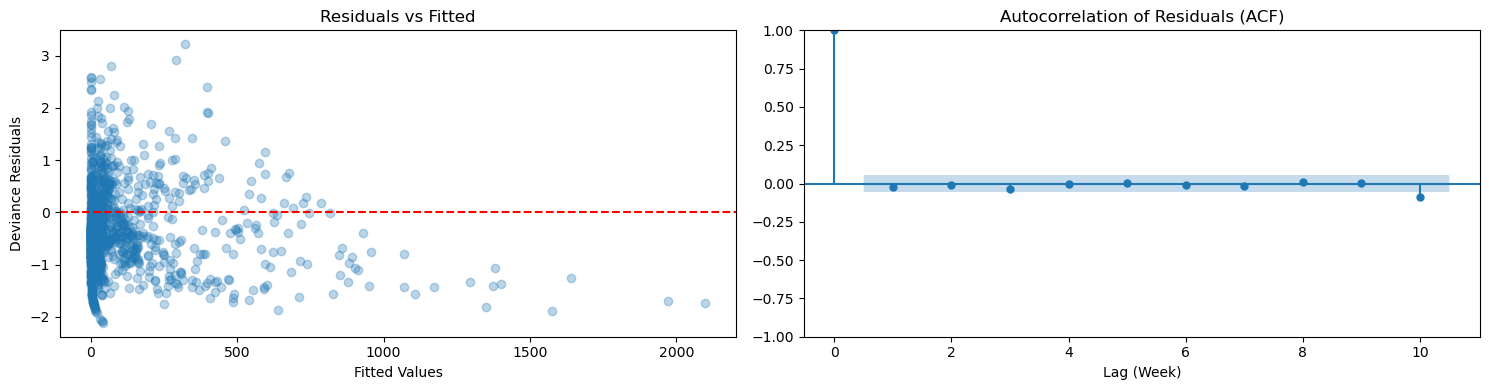

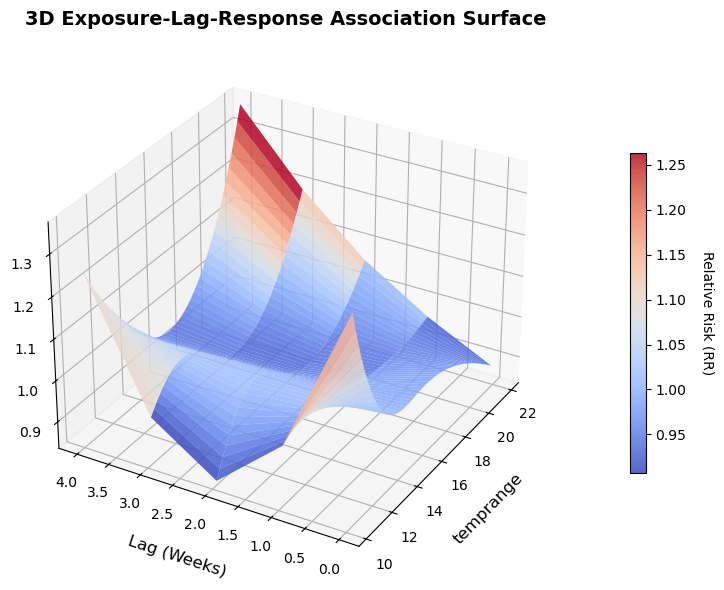

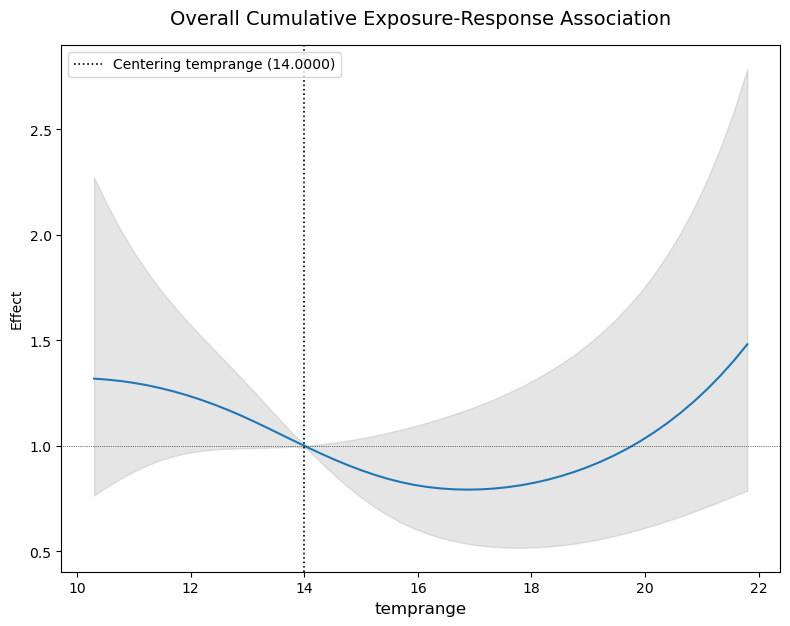

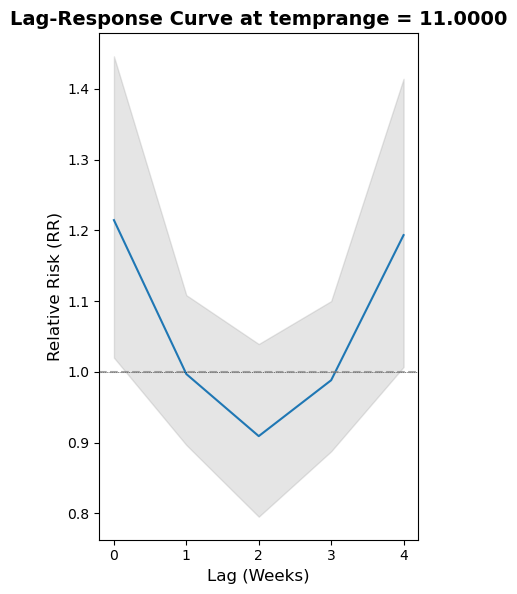

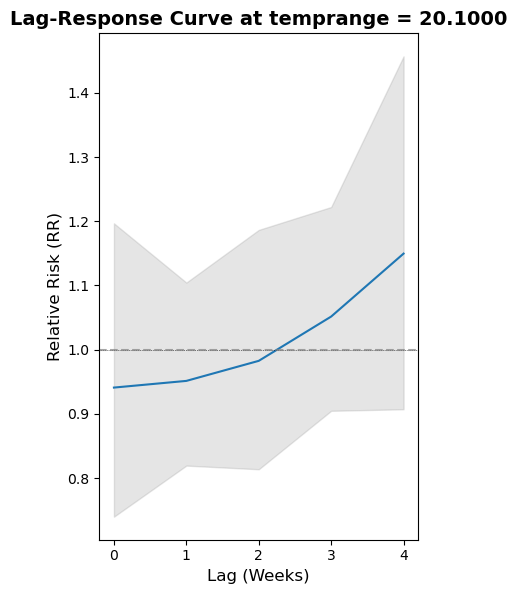

**====================================================================== temp ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 11849.16
BIC for (2, 3, 2, 4): 11902.03
BIC for (2, 3, 3, 3): 11849.16
BIC for (2, 3, 3, 4): 11902.03
BIC for (2, 4, 2, 3): 11804.45
BIC for (2, 4, 2, 4): 11863.71
BIC for (2, 4, 3, 3): 11804.45
BIC for (2, 4, 3, 4): 11863.71
BIC for (3, 3, 2, 3): 11849.16
BIC for (3, 3, 2, 4): 11902.03
BIC for (3, 3, 3, 3): 11849.16
BIC for (3, 3, 3, 4): 11902.03
BIC for (3, 4, 2, 3): 11804.45
BIC for (3, 4, 2, 4): 11863.71
BIC for (3, 4, 3, 3): 11804.45
BIC for (3, 4, 3, 4): 11863.71
Best CrossBasis setting: (2, 4, 2, 3) (BIC = 11804.45)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=11233.4690 | sum(EDF)=31.6417
Degrees of freedom (10, 4, 6): BIC=11115.3380 | sum(EDF)=32.1268
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.6298400281264566e+17, 2.62490540245921e-53,...",22203.330425,22203.330425,1.0,0.0
KFold,"(1.0, 125.89254117941663, 1995262.3149688789)",10039.532905,10260.961913,1.072944,43.16946



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.9902 | BIC = 10260.9619
Dispersion   1.5: Pearson ratio = 1.4196 | BIC = 10155.1723
Dispersion   2.0: Pearson ratio = 1.1158 | BIC = 10195.1730
Dispersion   3.0: Pearson ratio = 0.7923 | BIC = 10378.8096
Dispersion   4.0: Pearson ratio = 0.6209 | BIC = 10588.2677
Dispersion   5.0: Pearson ratio = 0.5134 | BIC = 10789.0247

Best dispersion parameter: 2.0 (Pearson ratio = 1.1158)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1204.74
Model Family:        NegativeBinomial   Df Model:                        42.26
Link Function:                

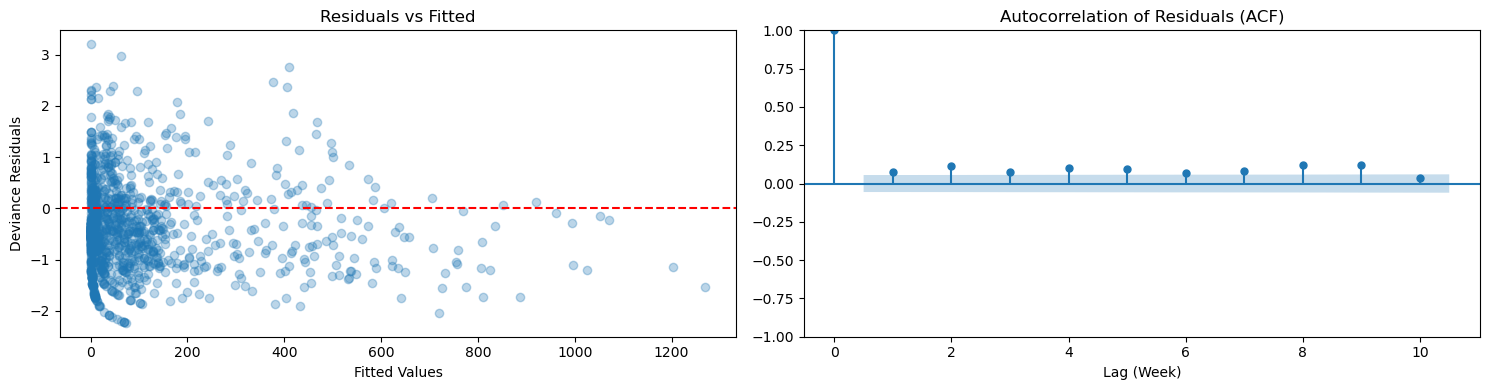

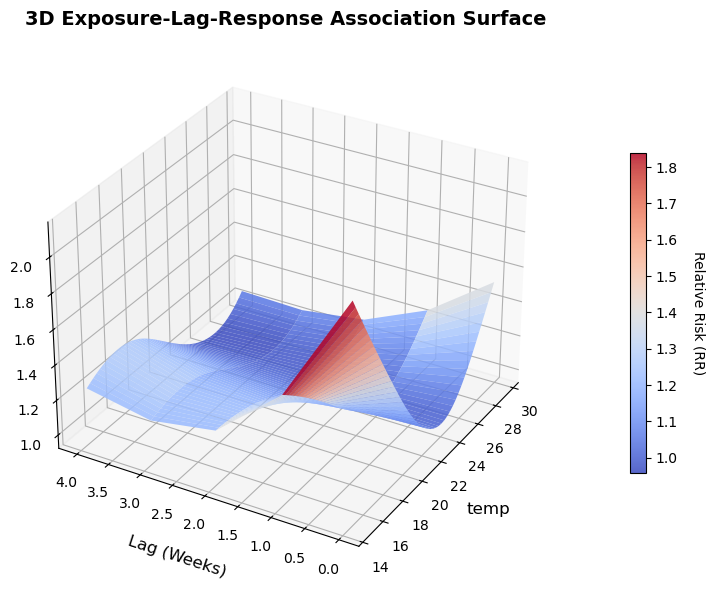

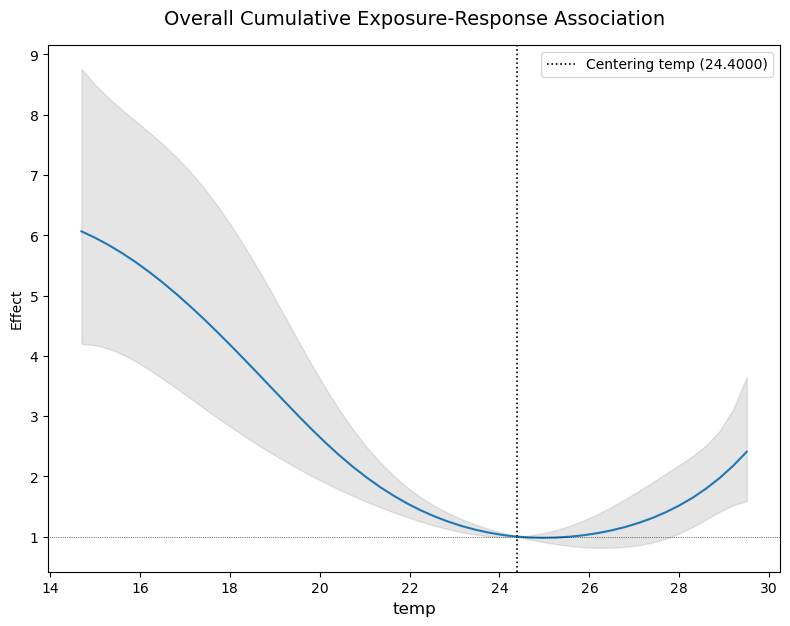

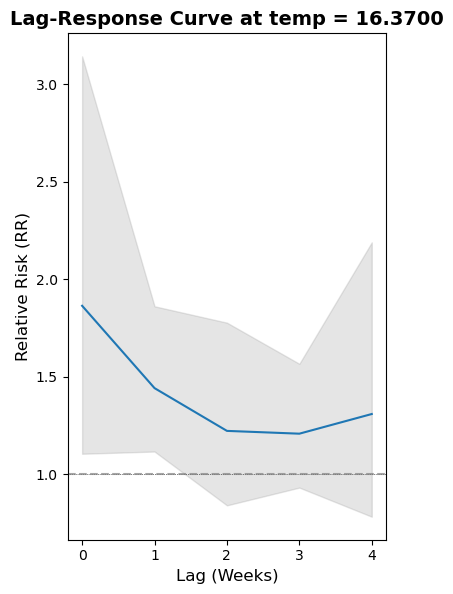

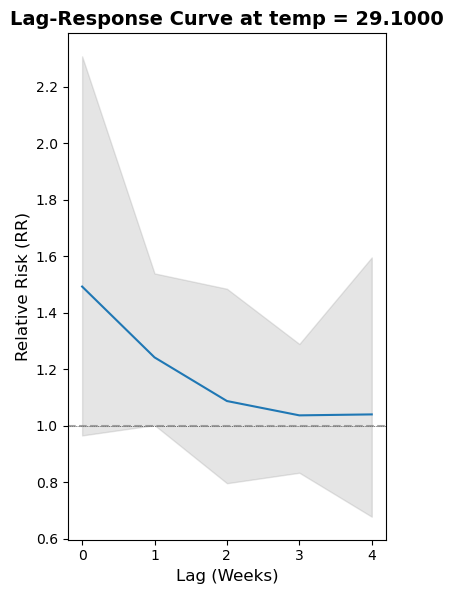

**====================================================================== RH ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 12551.90
BIC for (2, 3, 2, 4): 12085.48
BIC for (2, 3, 3, 3): 12551.90
BIC for (2, 3, 3, 4): 12085.48
BIC for (2, 4, 2, 3): 12162.72
BIC for (2, 4, 2, 4): 12400.94
BIC for (2, 4, 3, 3): 12162.72
BIC for (2, 4, 3, 4): 12400.94
BIC for (3, 3, 2, 3): 12551.90
BIC for (3, 3, 2, 4): 12085.48
BIC for (3, 3, 3, 3): 12551.90
BIC for (3, 3, 3, 4): 12085.48
BIC for (3, 4, 2, 3): 12162.72
BIC for (3, 4, 2, 4): 12400.94
BIC for (3, 4, 3, 3): 12162.72
BIC for (3, 4, 3, 4): 12400.94
Best CrossBasis setting: (2, 3, 2, 4) (BIC = 12085.48)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=11893.2047 | sum(EDF)=36.2870
Degrees of freedom (10, 4, 6): BIC=11138.9801 | sum(EDF)=31.7963
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[19.999999999999996, 19.999999999999996, 19.99...",9765.577135,10014.139177,1.082428,48.459275
KFold,"(25.118864315095795, 25.118864315095795, 630.9...",9796.04253,10067.316832,1.090464,52.887223



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.9082 | BIC = 10067.3168
Dispersion   1.5: Pearson ratio = 1.4022 | BIC = 9996.2439
Dispersion   2.0: Pearson ratio = 1.1318 | BIC = 10133.2317
Dispersion   3.0: Pearson ratio = 0.8257 | BIC = 10307.2300
Dispersion   4.0: Pearson ratio = 0.6673 | BIC = 10559.3052
Dispersion   5.0: Pearson ratio = 0.5656 | BIC = 10762.9202

Best dispersion parameter: 2.0 (Pearson ratio = 1.1318)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1197.03
Model Family:        NegativeBinomial   Df Model:                        49.97
Link Function:                 

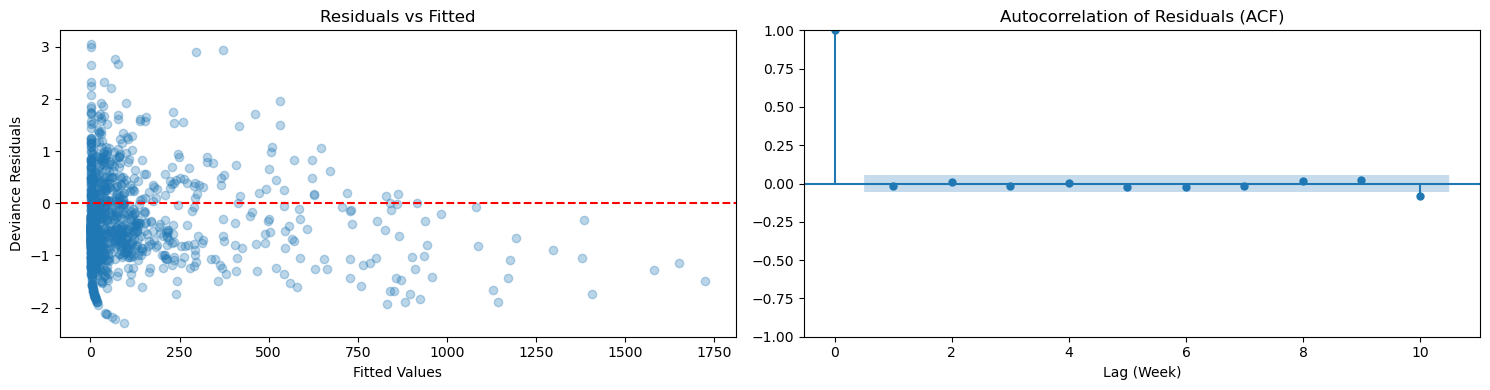

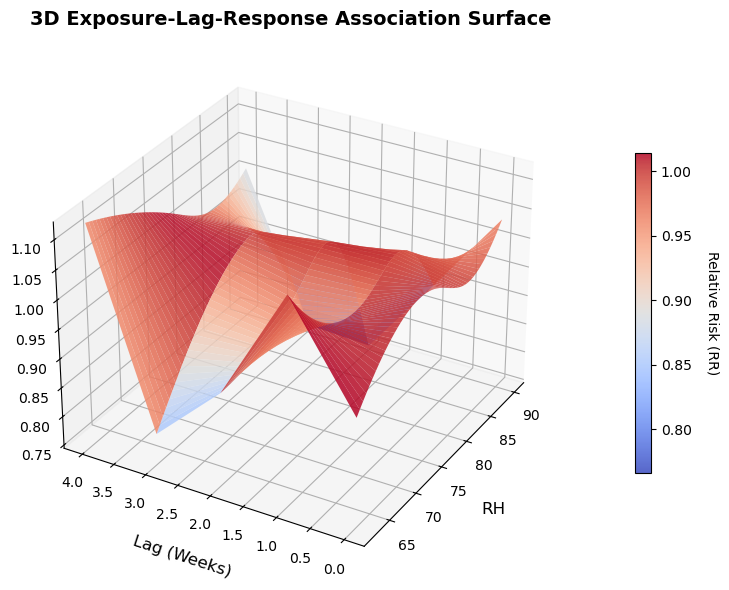

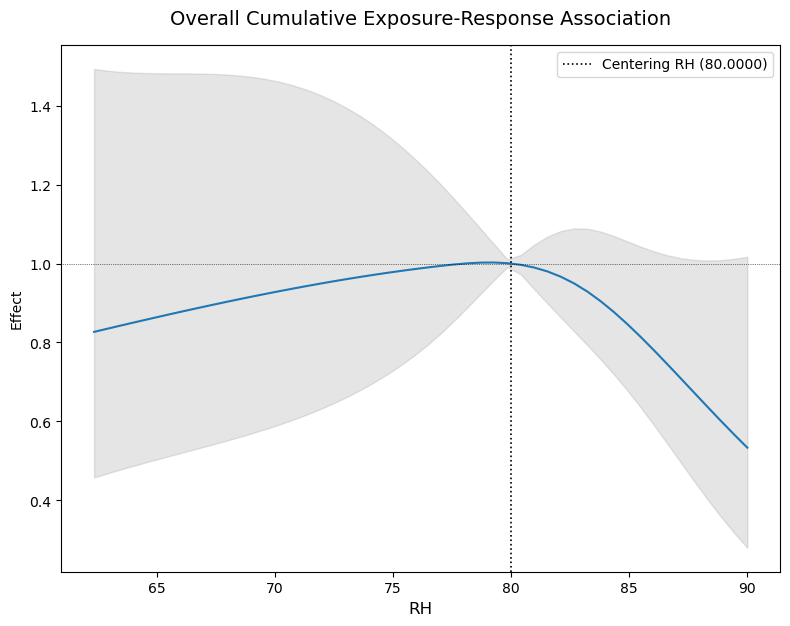

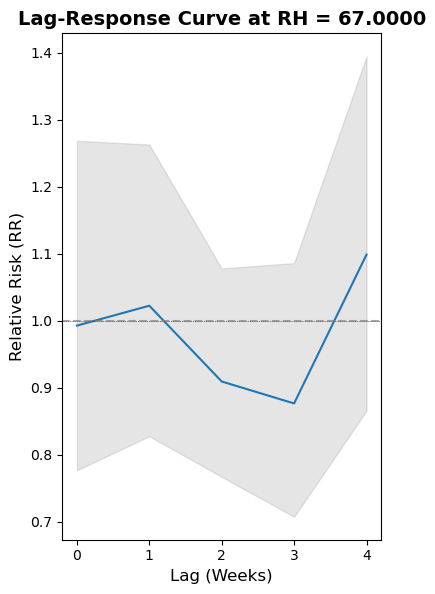

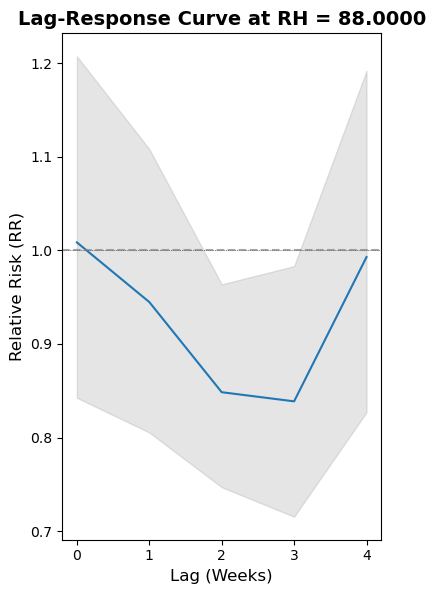

**====================================================================== SR ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 11950.12
BIC for (2, 3, 2, 4): 12075.60
BIC for (2, 3, 3, 3): 11950.12
BIC for (2, 3, 3, 4): 12075.60
BIC for (2, 4, 2, 3): 12112.70
option (2, 4, 2, 4) failed: SVD did not converge
BIC for (2, 4, 2, 4): failed
BIC for (2, 4, 3, 3): 12112.70
option (2, 4, 3, 4) failed: SVD did not converge
BIC for (2, 4, 3, 4): failed
BIC for (3, 3, 2, 3): 11950.12
BIC for (3, 3, 2, 4): 12075.60
BIC for (3, 3, 3, 3): 11950.12
BIC for (3, 3, 3, 4): 12075.60
BIC for (3, 4, 2, 3): 12112.70
option (3, 4, 2, 4) failed: SVD did not converge
BIC for (3, 4, 2, 4): failed
BIC for (3, 4, 3, 3): 12112.70
option (3, 4, 3, 4) failed: SVD did not converge
BIC for (3, 4, 3, 4): failed
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 11950.12)

============================== Tuning smoother 

,alpha,AIC,BIC,GCV,EDF
gcv,"[11.465419313215055, 25.462989204799435, 57.10...",9780.079395,10083.361165,1.101941,59.12735
KFold,"(398107.1705534969, 3162.2776601683795, 1.0)",10159.459656,10311.669506,1.049307,29.674599



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 3.0735 | BIC = 10311.6695
Dispersion   1.5: Pearson ratio = 2.6739 | BIC = 10276.2006
Dispersion   2.0: Pearson ratio = 2.3297 | BIC = 10329.8460
Dispersion   3.0: Pearson ratio = 1.8194 | BIC = 10477.6575
Dispersion   4.0: Pearson ratio = 1.4809 | BIC = 10650.0205
Dispersion   5.0: Pearson ratio = 1.2468 | BIC = 10839.9082

Best dispersion parameter: 5.0 (Pearson ratio = 1.2468)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1217.40
Model Family:        NegativeBinomial   Df Model:                        29.60
Link Function:                

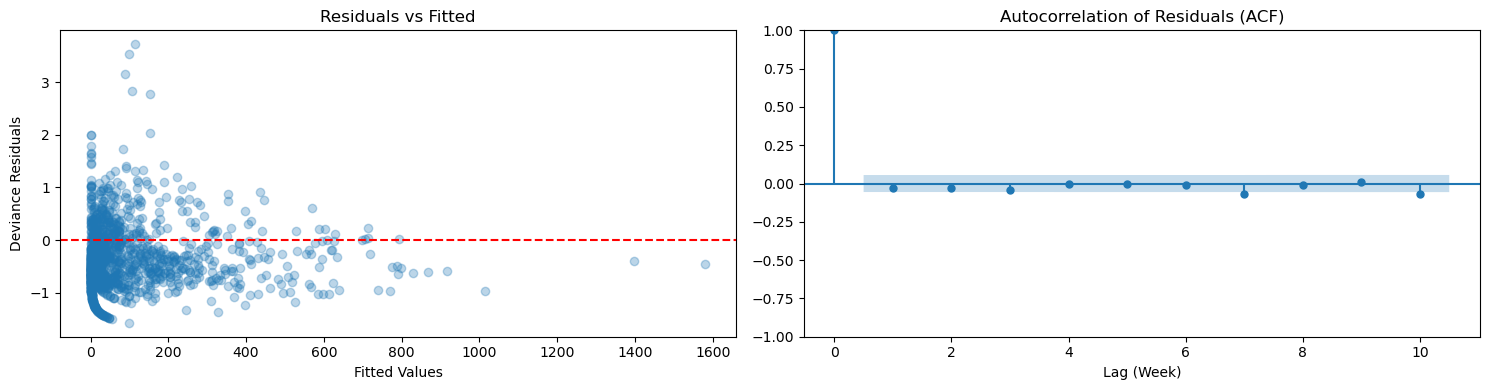

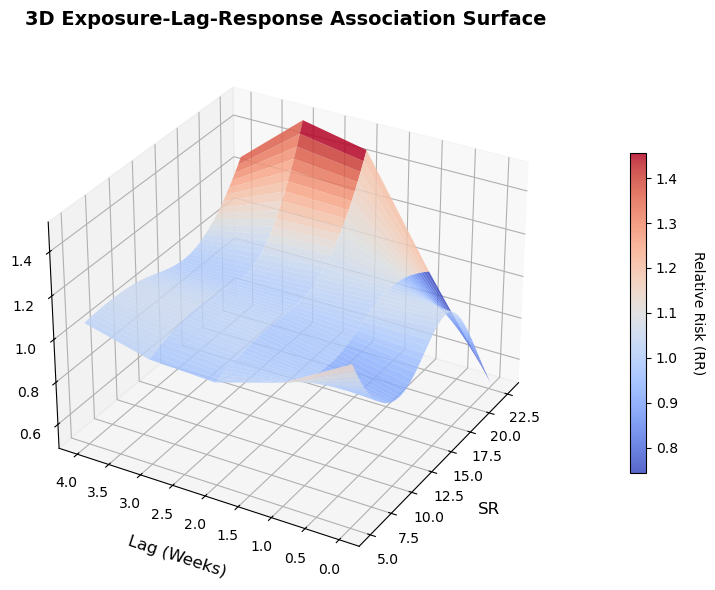

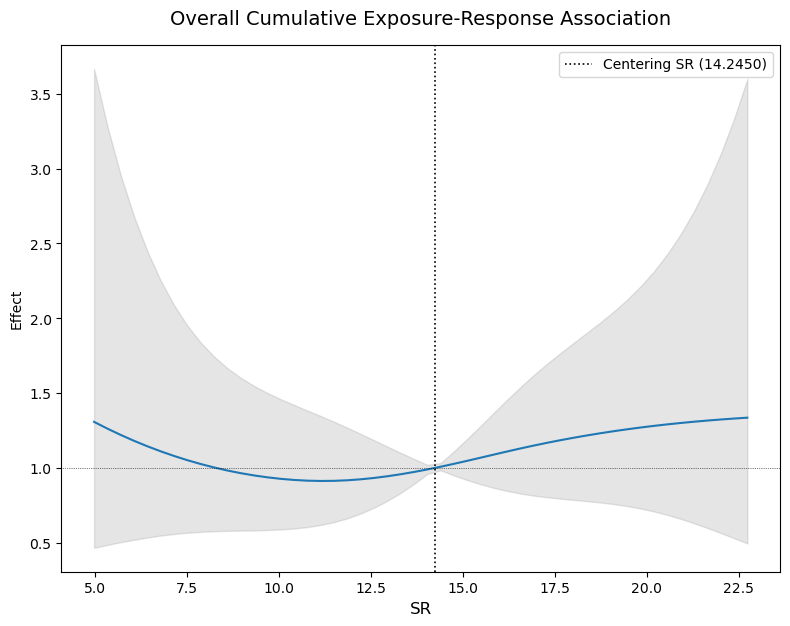

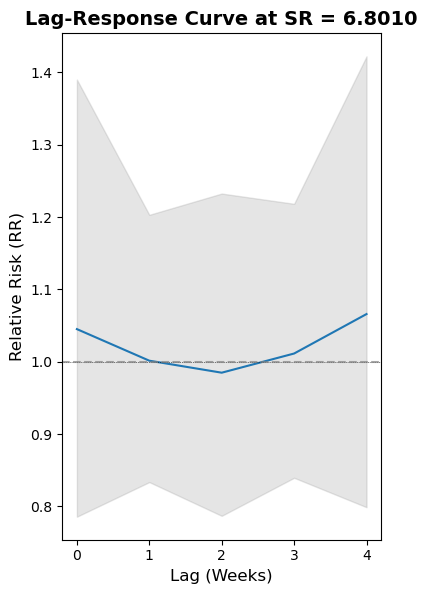

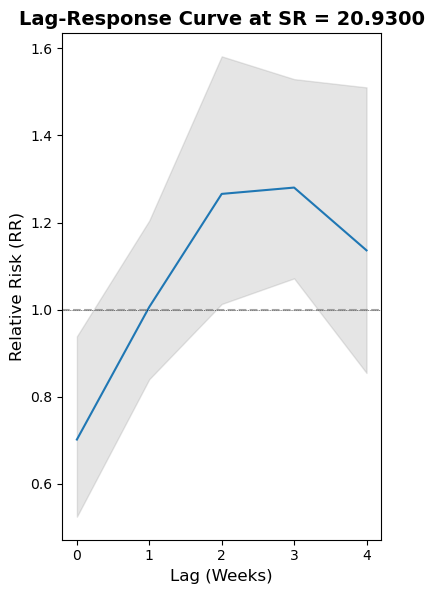

**====================================================================== AP ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 12020.74
BIC for (2, 3, 2, 4): 12033.02
BIC for (2, 3, 3, 3): 12020.74
BIC for (2, 3, 3, 4): 12033.02
BIC for (2, 4, 2, 3): 12112.36
BIC for (2, 4, 2, 4): 12020.32
BIC for (2, 4, 3, 3): 12112.36
BIC for (2, 4, 3, 4): 12020.32
BIC for (3, 3, 2, 3): 12020.74
BIC for (3, 3, 2, 4): 12033.02
BIC for (3, 3, 3, 3): 12020.74
BIC for (3, 3, 3, 4): 12033.02
BIC for (3, 4, 2, 3): 12112.36
BIC for (3, 4, 2, 4): 12020.32
BIC for (3, 4, 3, 3): 12112.36
BIC for (3, 4, 3, 4): 12020.32
Best CrossBasis setting: (2, 4, 2, 4) (BIC = 12020.32)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=11268.6102 | sum(EDF)=34.7719
Degrees of freedom (10, 4, 6): BIC=11168.0950 | sum(EDF)=35.2525
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[3536.2759580865672, 1.1587091633953665e-16, 1...",22203.330425,22203.330425,1.0,0.0
KFold,"(125.89254117941663, 3162.2776601683795, 3162....",9944.827014,10187.955361,1.080519,47.39993



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 2.1891 | BIC = 10187.9554
Dispersion   1.5: Pearson ratio = 1.6130 | BIC = 10110.8877
Dispersion   2.0: Pearson ratio = 1.2716 | BIC = 10176.5281
Dispersion   3.0: Pearson ratio = 0.8997 | BIC = 10384.3894
Dispersion   4.0: Pearson ratio = 0.6998 | BIC = 10602.8965
Dispersion   5.0: Pearson ratio = 0.5749 | BIC = 10807.9556

Best dispersion parameter: 3.0 (Pearson ratio = 0.8997)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1203.49
Model Family:        NegativeBinomial   Df Model:                        43.51
Link Function:                

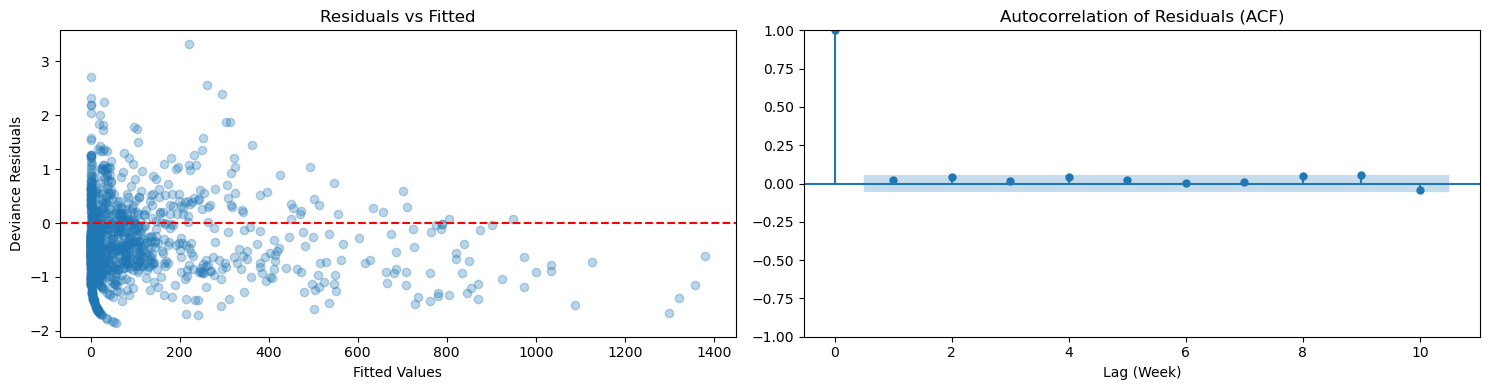

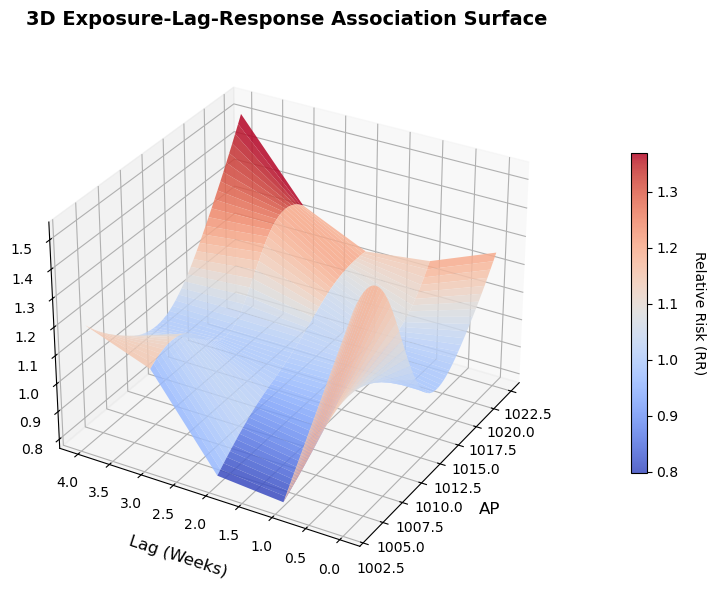

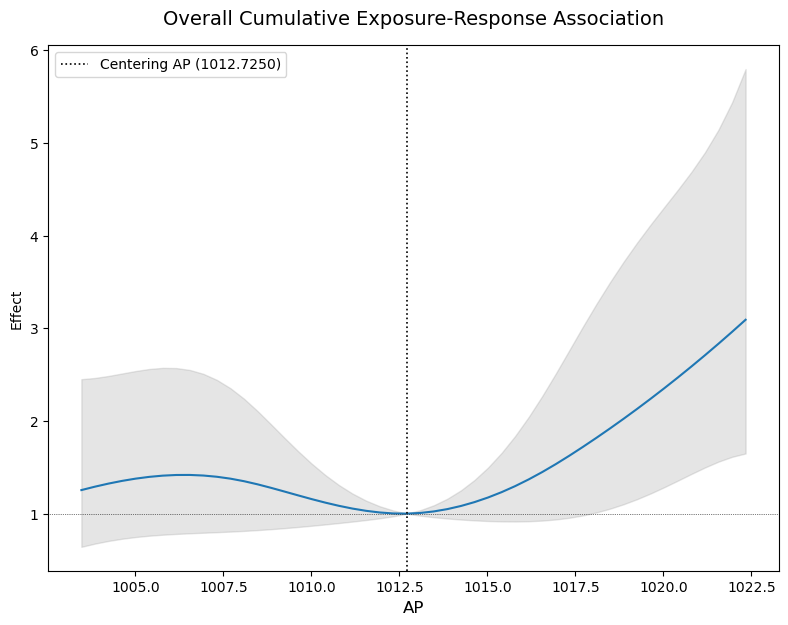

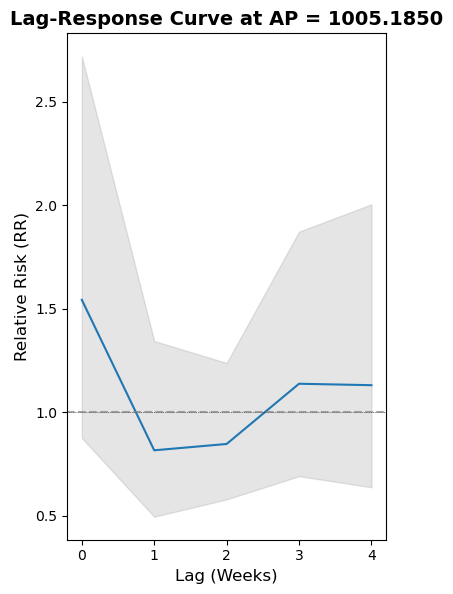

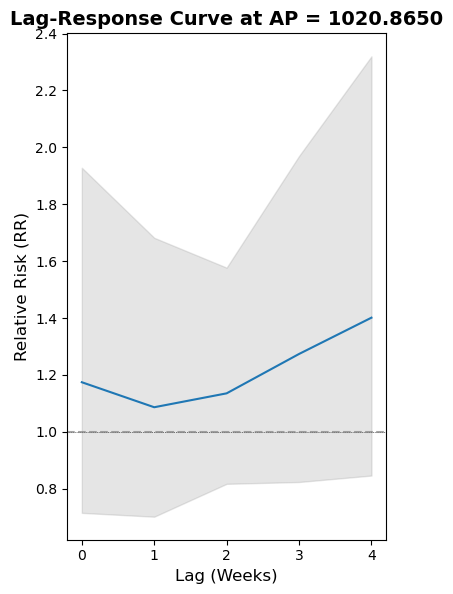

**====================================================================== DPT ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 11925.12
BIC for (2, 3, 2, 4): 11702.81
BIC for (2, 3, 3, 3): 11925.12
BIC for (2, 3, 3, 4): 11702.81
BIC for (2, 4, 2, 3): 11775.41
BIC for (2, 4, 2, 4): 11602.12
BIC for (2, 4, 3, 3): 11775.41
BIC for (2, 4, 3, 4): 11602.12
BIC for (3, 3, 2, 3): 11925.12
BIC for (3, 3, 2, 4): 11702.81
BIC for (3, 3, 3, 3): 11925.12
BIC for (3, 3, 3, 4): 11702.81
BIC for (3, 4, 2, 3): 11775.41
BIC for (3, 4, 2, 4): 11602.12
BIC for (3, 4, 3, 3): 11775.41
BIC for (3, 4, 3, 4): 11602.12
Best CrossBasis setting: (2, 4, 2, 4) (BIC = 11602.12)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=11013.1699 | sum(EDF)=34.5675
Degrees of freedom (10, 4, 6): BIC=10959.9944 | sum(EDF)=35.2593
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[19.999999999999996, 19.999999999999996, 19.99...",9762.384943,10028.212376,1.088529,51.825309
KFold,"(3162.2776601683795, 1.0, 125.89254117941663)",9763.443014,10017.713068,1.08444,49.572101



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.8034 | BIC = 10017.7131
Dispersion   1.5: Pearson ratio = 1.3160 | BIC = 10006.3738
Dispersion   2.0: Pearson ratio = 1.0504 | BIC = 10095.0623
Dispersion   3.0: Pearson ratio = 0.7646 | BIC = 10329.5393
Dispersion   4.0: Pearson ratio = 0.6087 | BIC = 10562.5765
Dispersion   5.0: Pearson ratio = 0.5091 | BIC = 10776.3211

Best dispersion parameter: 2.0 (Pearson ratio = 1.0504)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1198.88
Model Family:        NegativeBinomial   Df Model:                        48.12
Link Function:                

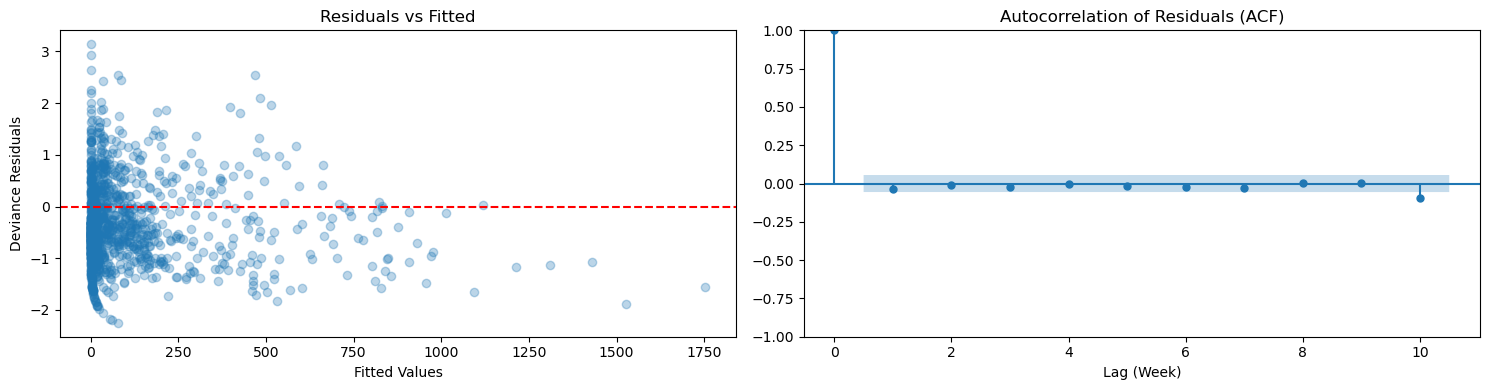

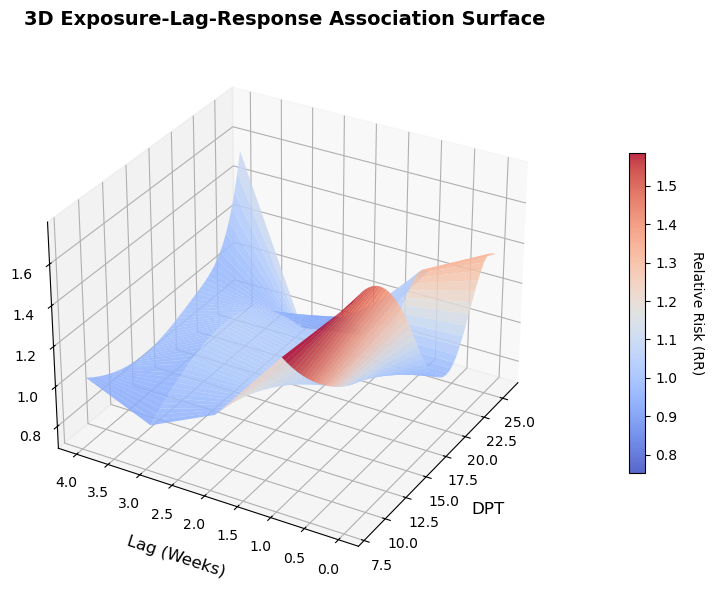

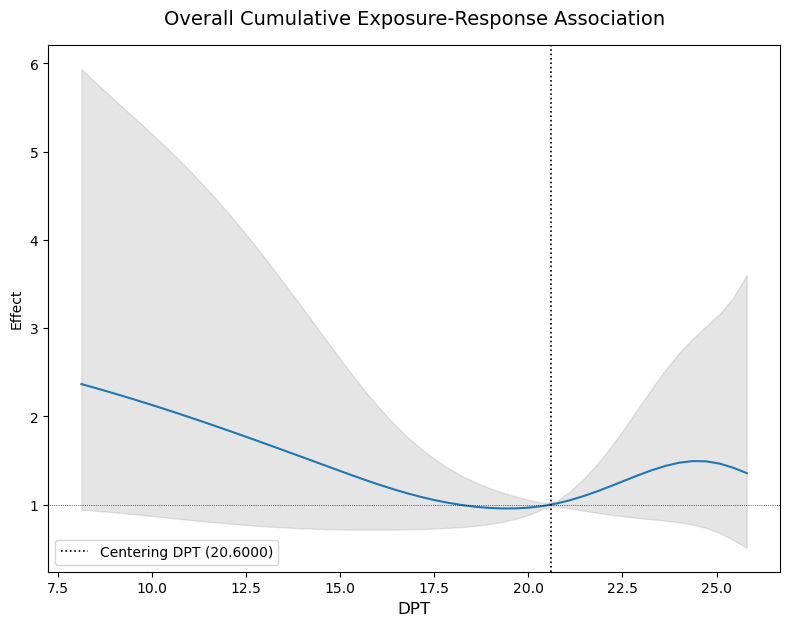

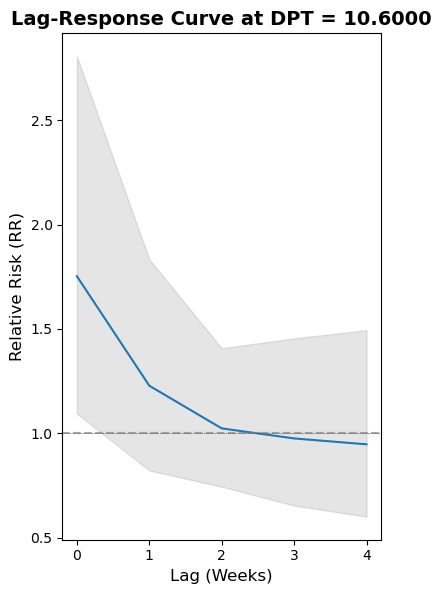

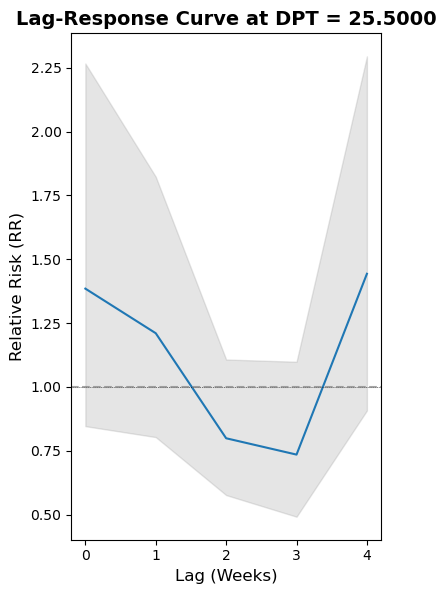

**====================================================================== WS ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 12144.75
BIC for (2, 3, 2, 4): 12077.18
BIC for (2, 3, 3, 3): 12144.75
BIC for (2, 3, 3, 4): 12077.18
BIC for (2, 4, 2, 3): 12059.02
BIC for (2, 4, 2, 4): 12087.31
BIC for (2, 4, 3, 3): 12059.02
BIC for (2, 4, 3, 4): 12087.31
BIC for (3, 3, 2, 3): 12144.75
BIC for (3, 3, 2, 4): 12077.18
BIC for (3, 3, 3, 3): 12144.75
BIC for (3, 3, 3, 4): 12077.18
BIC for (3, 4, 2, 3): 12059.02
BIC for (3, 4, 2, 4): 12087.31
BIC for (3, 4, 3, 3): 12059.02
BIC for (3, 4, 3, 4): 12087.31
Best CrossBasis setting: (2, 4, 2, 3) (BIC = 12059.02)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=11236.6480 | sum(EDF)=29.6810
Degrees of freedom (10, 4, 6): BIC=11049.9984 | sum(EDF)=30.6060
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[11.016497647015736, 114.04197622581614, 218.2...",9802.334579,10108.771437,1.103083,59.742461
KFold,"(1.0, 5.011872336272722, 5.011872336272722)",9769.506662,10014.181697,1.081062,47.70147



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.8059 | BIC = 10014.1817
Dispersion   1.5: Pearson ratio = 1.3053 | BIC = 9995.1257
Dispersion   2.0: Pearson ratio = 1.0380 | BIC = 10080.1357
Dispersion   3.0: Pearson ratio = 0.7530 | BIC = 10313.6828
Dispersion   4.0: Pearson ratio = 0.5998 | BIC = 10547.8938
Dispersion   5.0: Pearson ratio = 0.4765 | BIC = 10779.2700

Best dispersion parameter: 2.0 (Pearson ratio = 1.0380)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1200.98
Model Family:        NegativeBinomial   Df Model:                        46.02
Link Function:                 

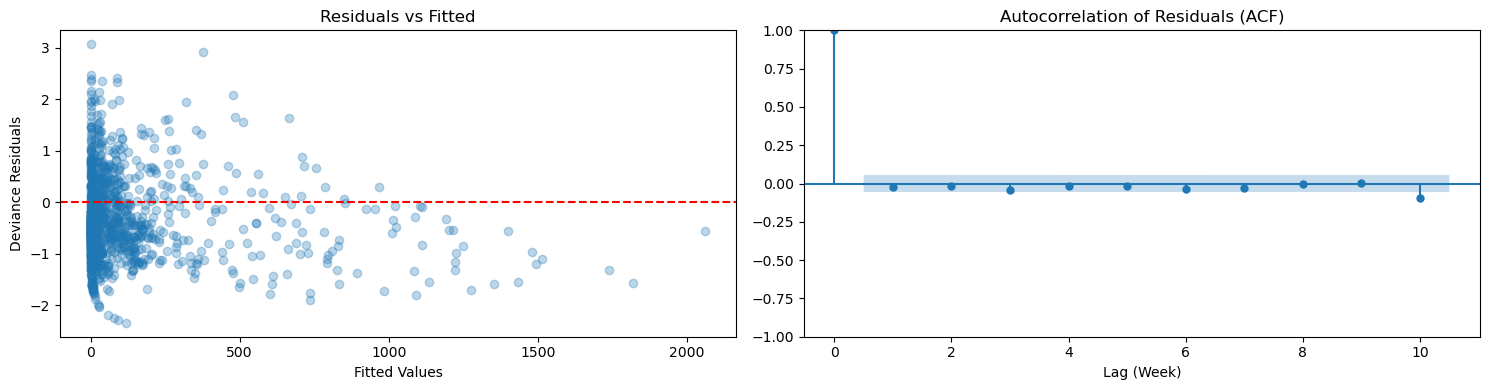

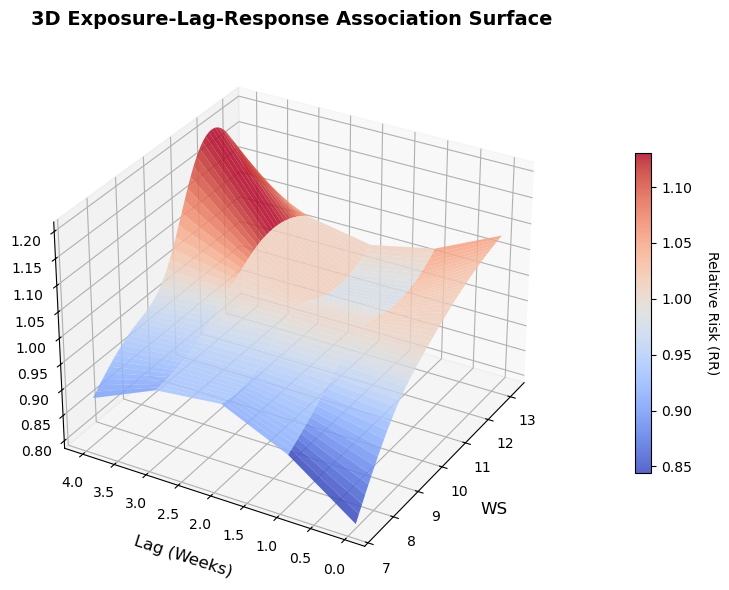

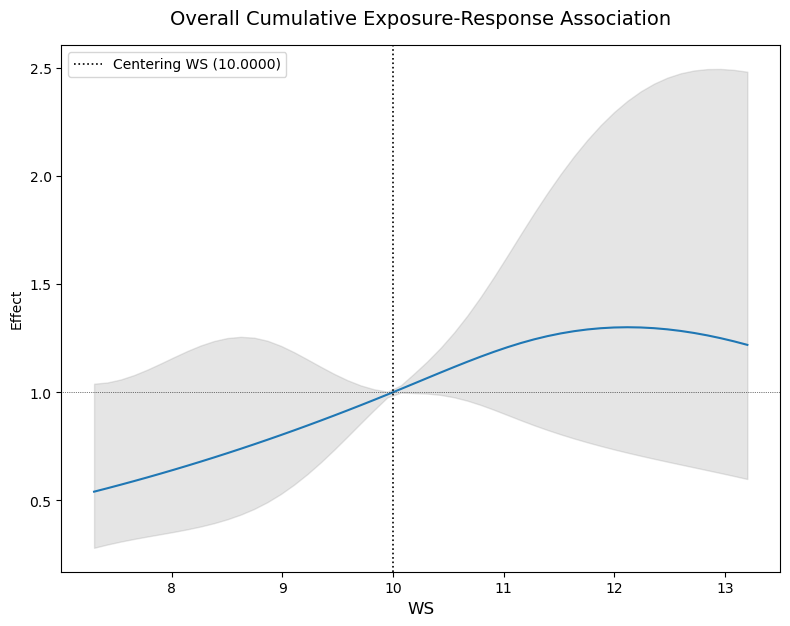

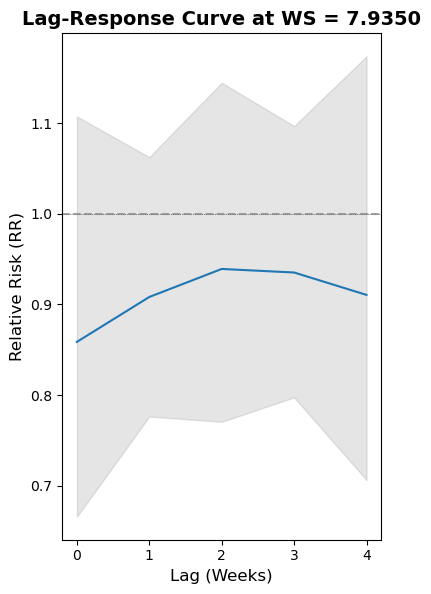

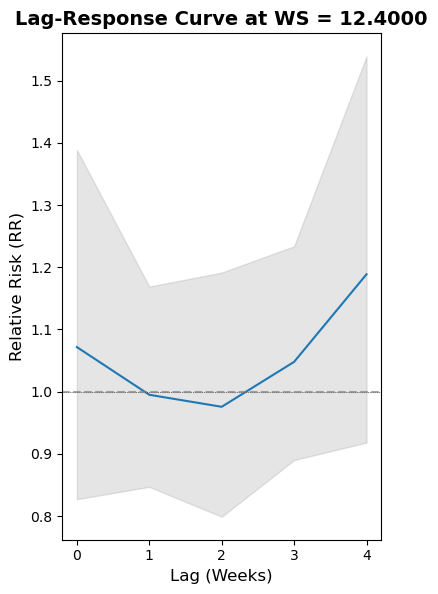

**====================================================================== UV ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 12034.95
BIC for (2, 3, 2, 4): 12103.29
BIC for (2, 3, 3, 3): 12034.95
BIC for (2, 3, 3, 4): 12103.29
BIC for (2, 4, 2, 3): 12086.27
BIC for (2, 4, 2, 4): 12121.73
BIC for (2, 4, 3, 3): 12086.27
BIC for (2, 4, 3, 4): 12121.73
BIC for (3, 3, 2, 3): 12034.95
BIC for (3, 3, 2, 4): 12103.29
BIC for (3, 3, 3, 3): 12034.95
BIC for (3, 3, 3, 4): 12103.29
BIC for (3, 4, 2, 3): 12086.27
BIC for (3, 4, 2, 4): 12121.73
BIC for (3, 4, 3, 3): 12086.27
BIC for (3, 4, 3, 4): 12121.73
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 12034.95)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=11208.4447 | sum(EDF)=28.1457
Degrees of freedom (10, 4, 6): BIC=11071.6493 | sum(EDF)=28.6809
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[23.101634376772626, 17.6519281604279, 107.359...",9801.711178,10096.461003,1.098864,57.463975
KFold,"(25.118864315095795, 5.011872336272722, 125.89...",9742.213531,9883.386102,1.04561,27.522788



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.8139 | BIC = 9883.3861
Dispersion   1.5: Pearson ratio = 1.3013 | BIC = 9933.7378
Dispersion   2.0: Pearson ratio = 1.0212 | BIC = 10011.1848
Dispersion   3.0: Pearson ratio = 0.7332 | BIC = 10323.7520
Dispersion   4.0: Pearson ratio = 0.5678 | BIC = 10434.8888
Dispersion   5.0: Pearson ratio = 0.4811 | BIC = 10832.6126

Best dispersion parameter: 2.0 (Pearson ratio = 1.0212)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1211.84
Model Family:        NegativeBinomial   Df Model:                        35.16
Link Function:                  

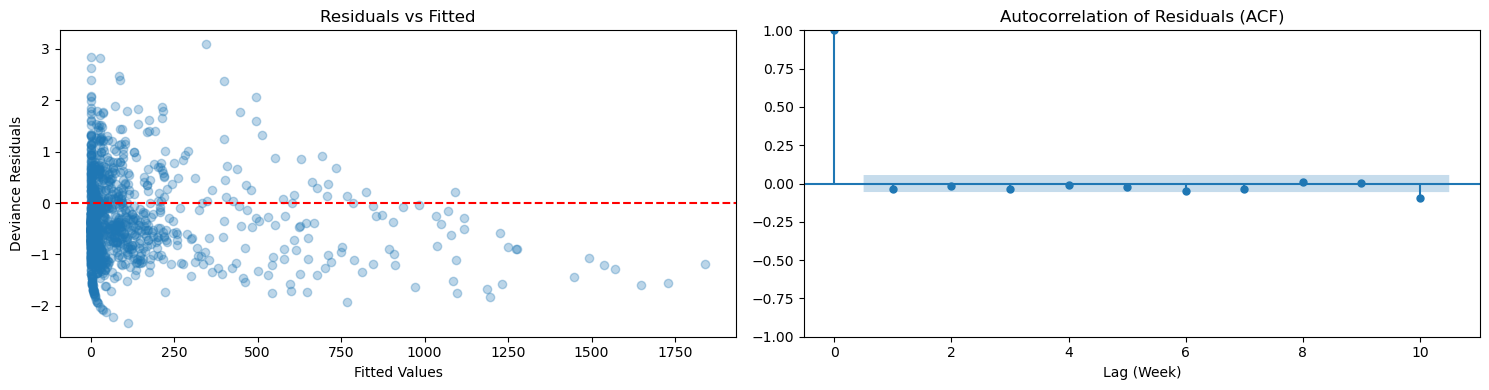

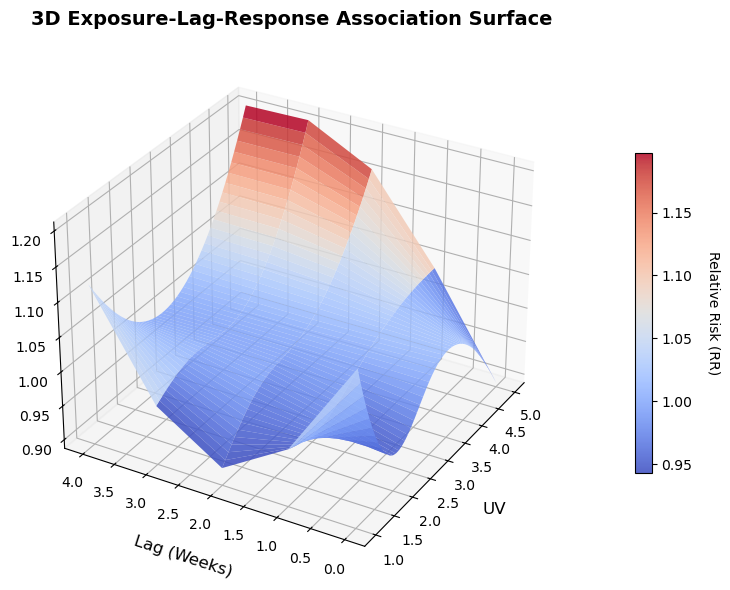

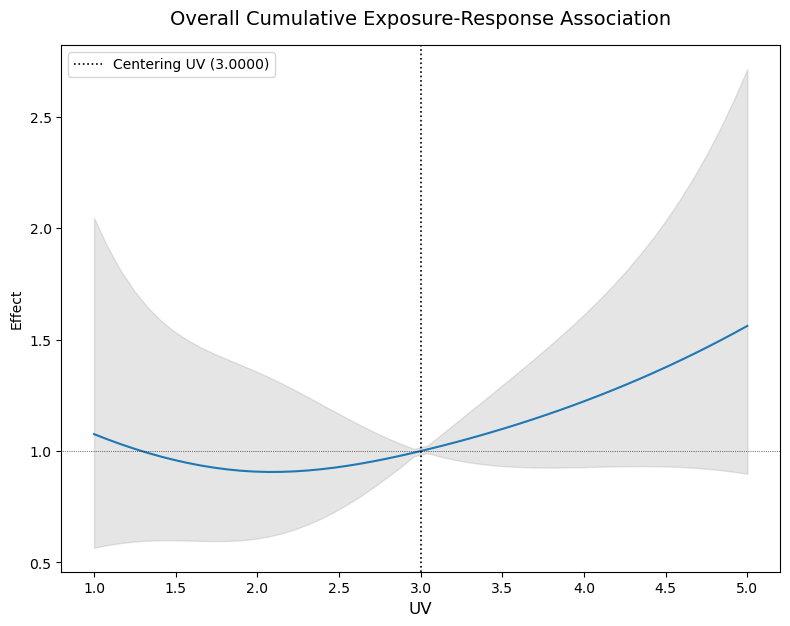

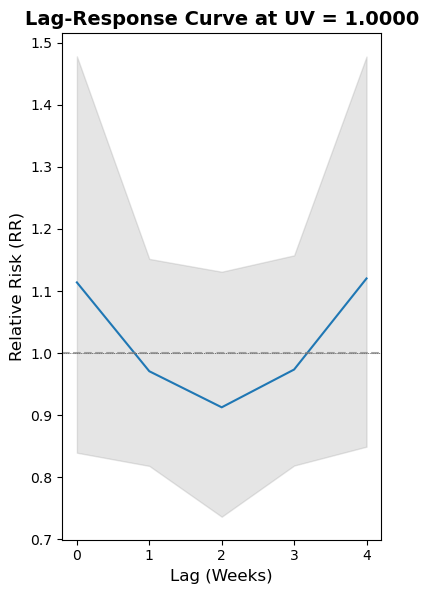

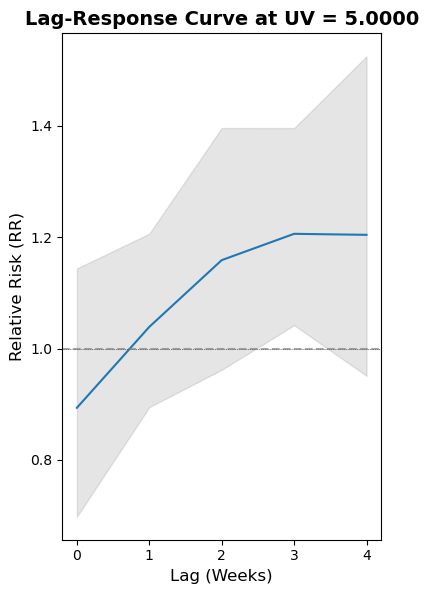

In [22]:
# All meteorological variables for H1
tar_var = "H1"
for exp in mete_col:
    exp_col_list = [exp]

    display(Markdown(f"**{'='*70} {exp} {'='*70}**"))

    pred, model_data, cb_list, nb_result = DLNM_NB(
        df, max_lag=4, tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list, bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
        cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=["gcv"]
    )


**====================================================================== temprange ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10361.91
BIC for (2, 3, 2, 4): 10380.12
BIC for (2, 3, 3, 3): 10361.91
BIC for (2, 3, 3, 4): 10380.12
BIC for (2, 4, 2, 3): 10368.99
BIC for (2, 4, 2, 4): 10391.40
BIC for (2, 4, 3, 3): 10368.99
BIC for (2, 4, 3, 4): 10391.40
BIC for (3, 3, 2, 3): 10361.91
BIC for (3, 3, 2, 4): 10380.12
BIC for (3, 3, 3, 3): 10361.91
BIC for (3, 3, 3, 4): 10380.12
BIC for (3, 4, 2, 3): 10368.99
BIC for (3, 4, 2, 4): 10391.40
BIC for (3, 4, 3, 3): 10368.99
BIC for (3, 4, 3, 4): 10391.40
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10361.91)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10181.0244 | sum(EDF)=28.7997
Degrees of freedom (10, 4, 6): BIC=10183.4221 | sum(EDF)=29.8077
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[7.01624122961891, 6713.706193335364, 379.2309...",10004.9393,10490.119074,1.170743,94.589906
KFold,"(125.89254117941663, 3162.2776601683795, 5.011...",9893.27115,10107.179984,1.070338,41.703339



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2010 | BIC = 10107.1800
Dispersion   1.5: Pearson ratio = 0.8336 | BIC = 10213.9497
Dispersion   2.0: Pearson ratio = 0.6421 | BIC = 10380.6040
Dispersion   3.0: Pearson ratio = 0.4433 | BIC = 10724.8473
Dispersion   4.0: Pearson ratio = 0.3402 | BIC = 11036.6747
Dispersion   5.0: Pearson ratio = 0.2768 | BIC = 11312.4402

Best dispersion parameter: 1.5 (Pearson ratio = 0.8336)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1206.34
Model Family:        NegativeBinomial   Df Model:                        40.66
Link Function:                

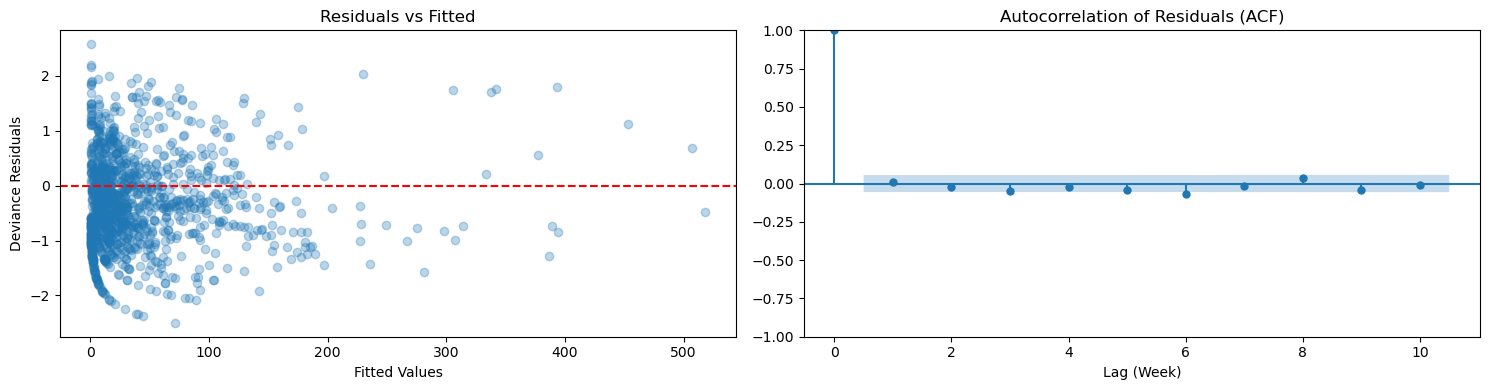

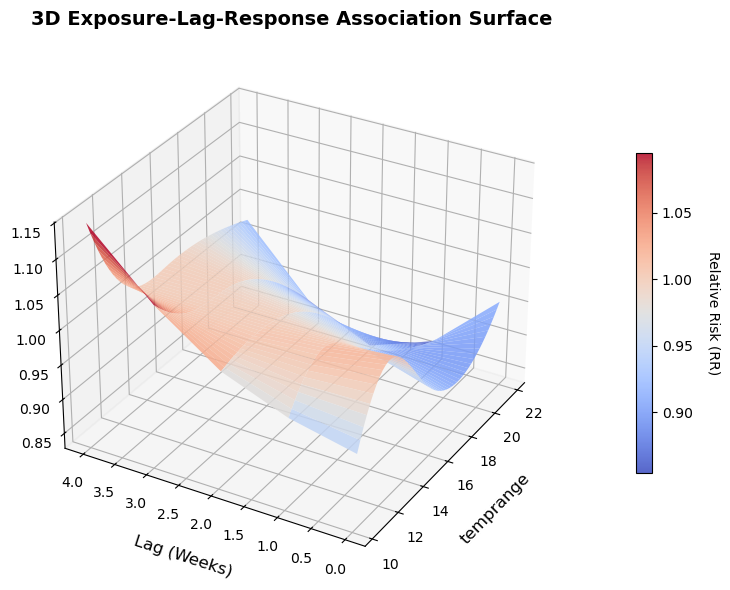

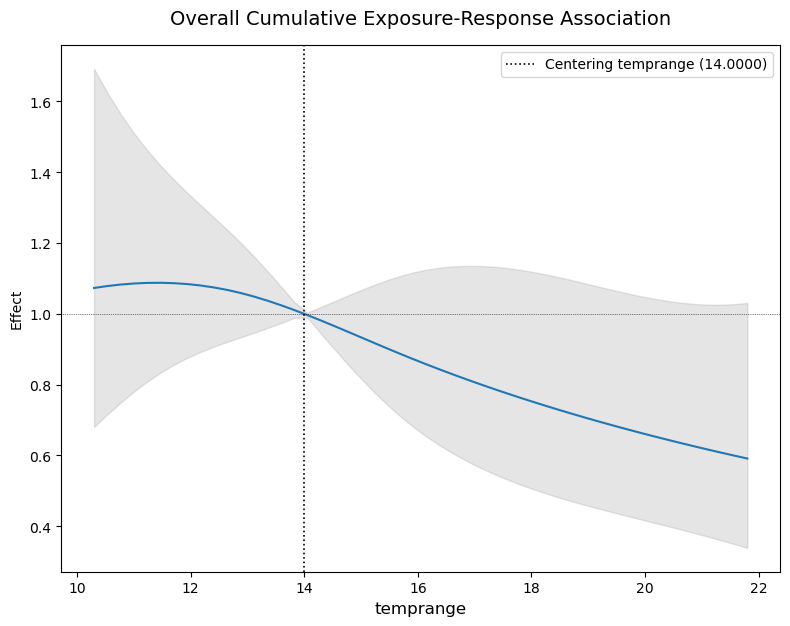

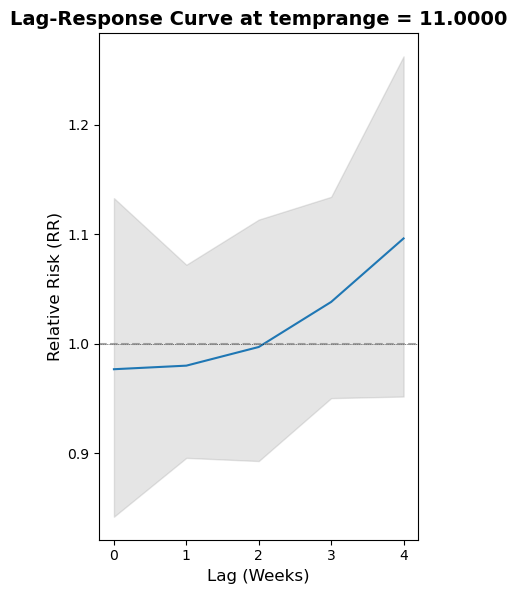

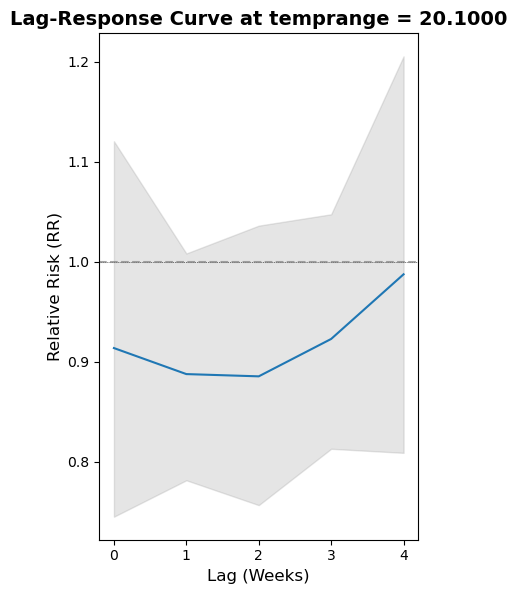

**====================================================================== temp ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10278.64
BIC for (2, 3, 2, 4): 10290.33
BIC for (2, 3, 3, 3): 10278.64
BIC for (2, 3, 3, 4): 10290.33
BIC for (2, 4, 2, 3): 10298.62
BIC for (2, 4, 2, 4): 10316.33
BIC for (2, 4, 3, 3): 10298.62
BIC for (2, 4, 3, 4): 10316.33
BIC for (3, 3, 2, 3): 10278.64
BIC for (3, 3, 2, 4): 10290.33
BIC for (3, 3, 3, 3): 10278.64
BIC for (3, 3, 3, 4): 10290.33
BIC for (3, 4, 2, 3): 10298.62
BIC for (3, 4, 2, 4): 10316.33
BIC for (3, 4, 3, 3): 10298.62
BIC for (3, 4, 3, 4): 10316.33
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10278.64)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10174.1164 | sum(EDF)=28.2926
Degrees of freedom (10, 4, 6): BIC=10179.9490 | sum(EDF)=29.2260
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[7.314881493129587, 27.759656840110424, 188.54...",9973.168893,10393.80462,1.14561,82.006498
KFold,"(15848.931924611108, 3162.2776601683795, 3162....",9926.208547,10120.152387,1.063464,37.810994



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2512 | BIC = 10120.1524
Dispersion   1.5: Pearson ratio = 0.8765 | BIC = 10203.4416
Dispersion   2.0: Pearson ratio = 0.6817 | BIC = 10379.6118
Dispersion   3.0: Pearson ratio = 0.4754 | BIC = 10707.8069
Dispersion   4.0: Pearson ratio = 0.3673 | BIC = 11005.7779
Dispersion   5.0: Pearson ratio = 0.3006 | BIC = 11275.3316

Best dispersion parameter: 1.5 (Pearson ratio = 0.8765)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1212.94
Model Family:        NegativeBinomial   Df Model:                        34.06
Link Function:                

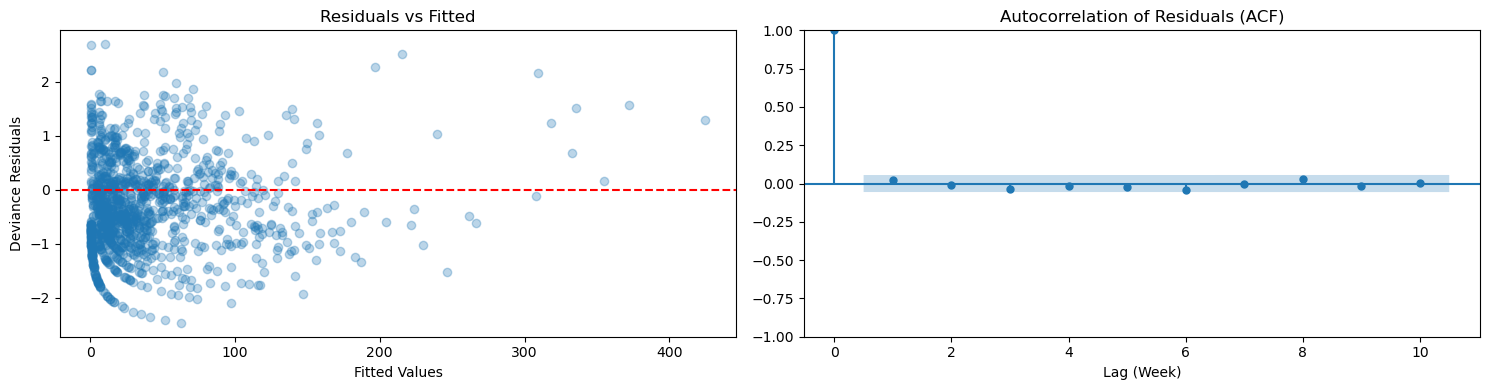

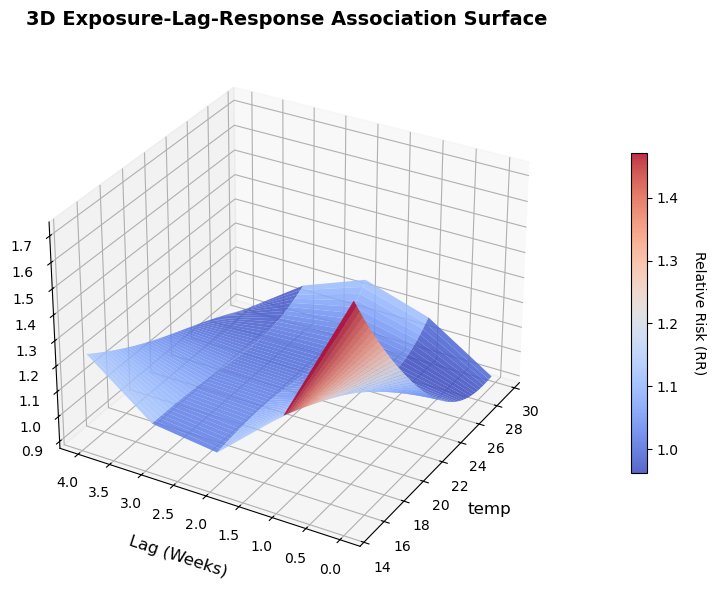

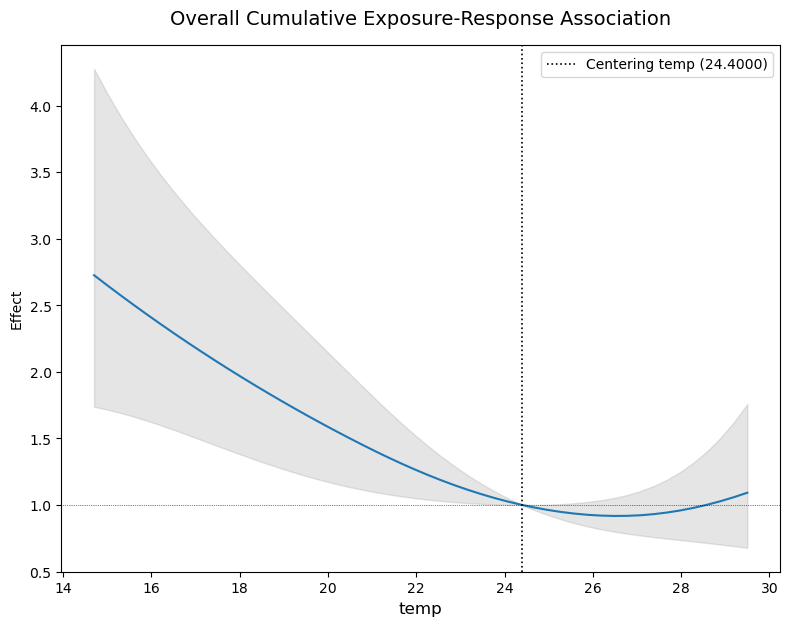

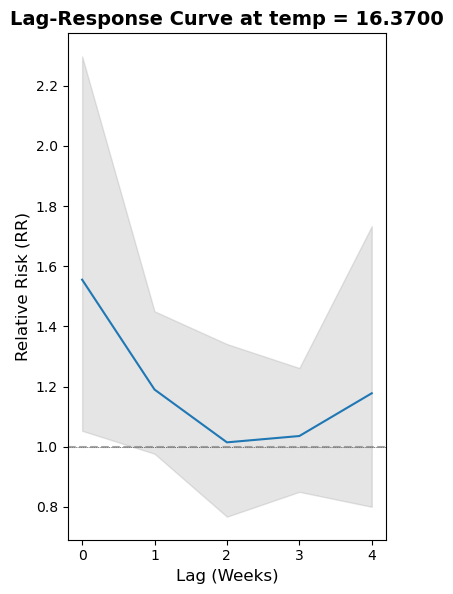

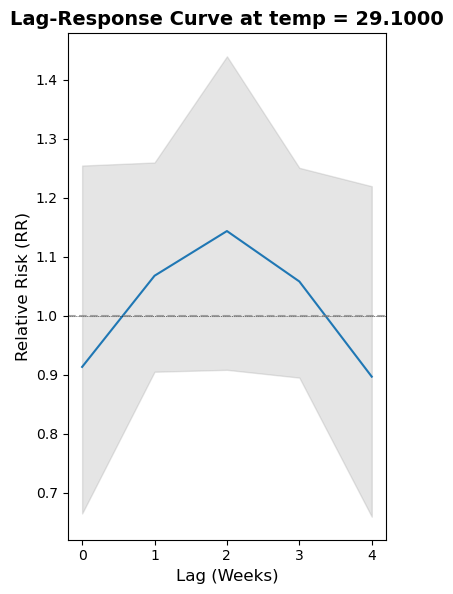

**====================================================================== RH ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10341.75
BIC for (2, 3, 2, 4): 10355.98
BIC for (2, 3, 3, 3): 10341.75
BIC for (2, 3, 3, 4): 10355.98
BIC for (2, 4, 2, 3): 10357.54
BIC for (2, 4, 2, 4): 10376.35
BIC for (2, 4, 3, 3): 10357.54
BIC for (2, 4, 3, 4): 10376.35
BIC for (3, 3, 2, 3): 10341.75
BIC for (3, 3, 2, 4): 10355.98
BIC for (3, 3, 3, 3): 10341.75
BIC for (3, 3, 3, 4): 10355.98
BIC for (3, 4, 2, 3): 10357.54
BIC for (3, 4, 2, 4): 10376.35
BIC for (3, 4, 3, 3): 10357.54
BIC for (3, 4, 3, 4): 10376.35
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10341.75)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10185.3731 | sum(EDF)=28.2832
Degrees of freedom (10, 4, 6): BIC=10186.2361 | sum(EDF)=29.1944
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.716500848916235e-07, 1.295829501187849e+41,...",22185.750636,22185.750636,1.0,0.0
KFold,"(79432.82347242805, 1.0, 630.957344480193)",9932.676743,10117.154665,1.060228,35.965533



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2292 | BIC = 10117.1547
Dispersion   1.5: Pearson ratio = 0.8639 | BIC = 10209.2968
Dispersion   2.0: Pearson ratio = 0.6721 | BIC = 10365.7306
Dispersion   3.0: Pearson ratio = 0.4711 | BIC = 10695.4886
Dispersion   4.0: Pearson ratio = 0.3643 | BIC = 10998.9782
Dispersion   5.0: Pearson ratio = 0.2986 | BIC = 11268.0925

Best dispersion parameter: 1.5 (Pearson ratio = 0.8639)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1213.07
Model Family:        NegativeBinomial   Df Model:                        33.93
Link Function:                

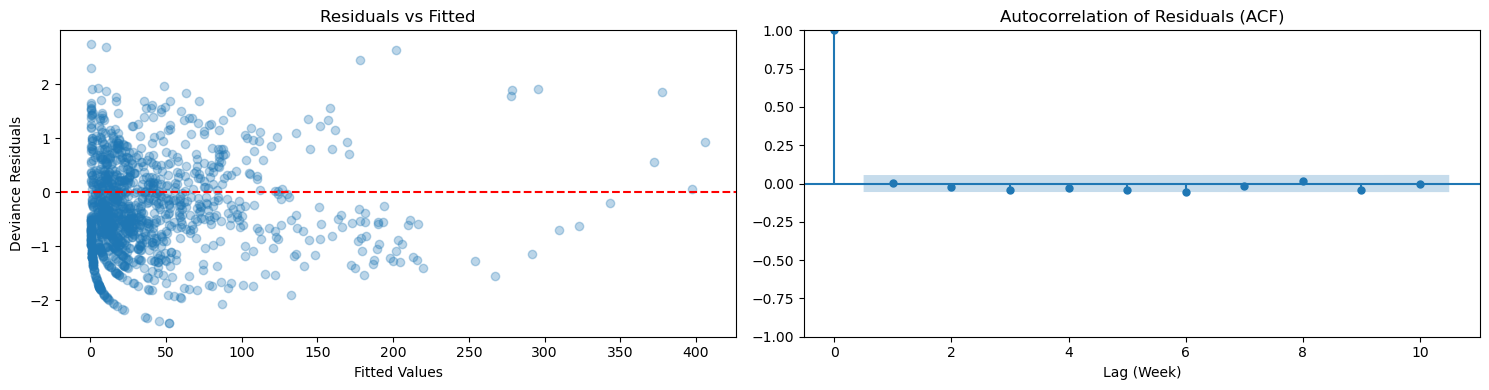

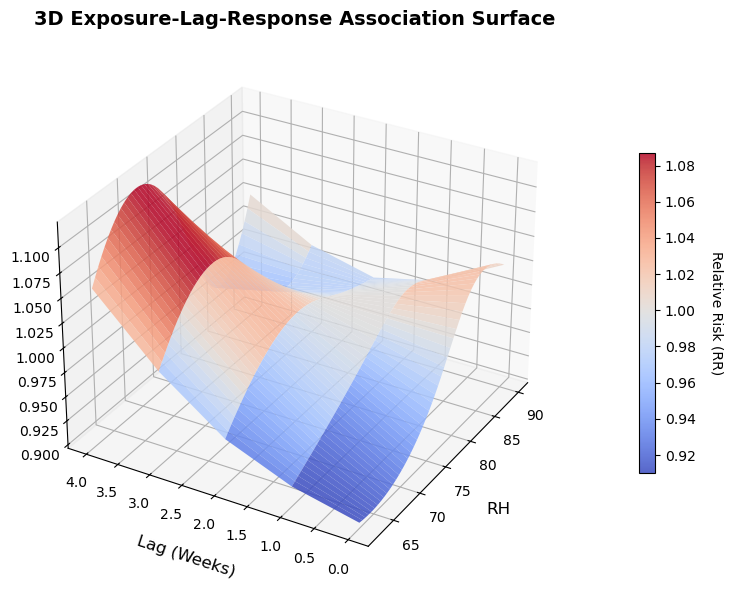

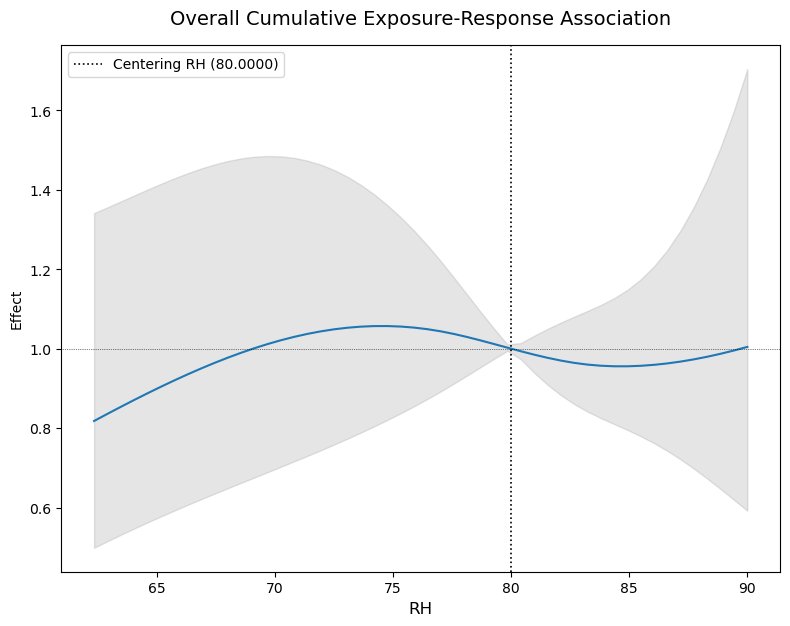

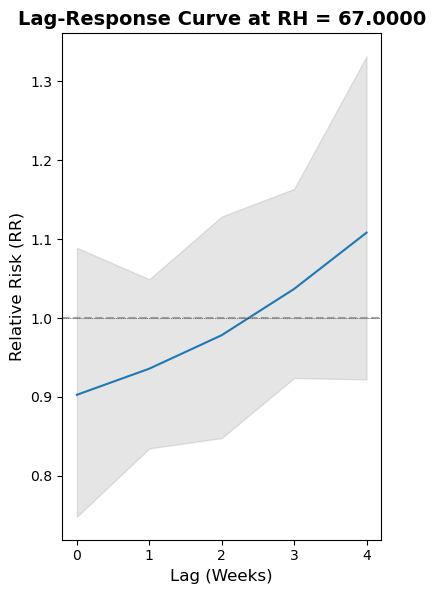

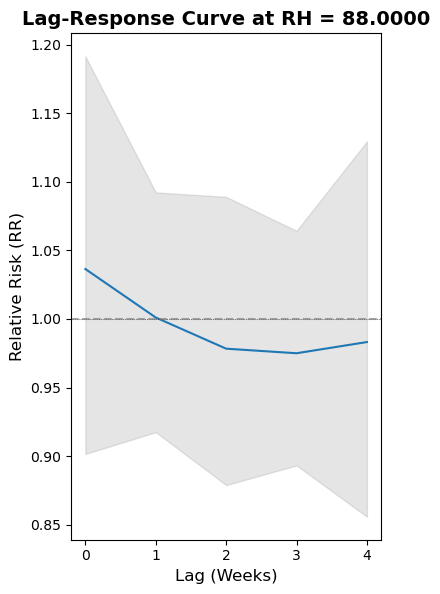

**====================================================================== SR ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10340.67
BIC for (2, 3, 2, 4): 10354.39
BIC for (2, 3, 3, 3): 10340.67
BIC for (2, 3, 3, 4): 10354.39
BIC for (2, 4, 2, 3): 10353.83
BIC for (2, 4, 2, 4): 10371.81
BIC for (2, 4, 3, 3): 10353.83
BIC for (2, 4, 3, 4): 10371.81
BIC for (3, 3, 2, 3): 10340.67
BIC for (3, 3, 2, 4): 10354.39
BIC for (3, 3, 3, 3): 10340.67
BIC for (3, 3, 3, 4): 10354.39
BIC for (3, 4, 2, 3): 10353.83
BIC for (3, 4, 2, 4): 10371.81
BIC for (3, 4, 3, 3): 10353.83
BIC for (3, 4, 3, 4): 10371.81
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10340.67)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10179.6594 | sum(EDF)=28.6709
Degrees of freedom (10, 4, 6): BIC=10179.0367 | sum(EDF)=29.5711
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[13.677024899645172, 56.59487189838613, 228.41...",9962.133786,10381.210846,1.145013,81.702622
KFold,"(10000000.0, 1.0, 3162.2776601683795)",10078.555814,10206.536357,1.041217,24.950891



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.4534 | BIC = 10206.5364
Dispersion   1.5: Pearson ratio = 1.0446 | BIC = 10254.0956
Dispersion   2.0: Pearson ratio = 0.8251 | BIC = 10387.0068
Dispersion   3.0: Pearson ratio = 0.5899 | BIC = 10691.1101
Dispersion   4.0: Pearson ratio = 0.4638 | BIC = 10981.1231
Dispersion   5.0: Pearson ratio = 0.3843 | BIC = 11241.7426

Best dispersion parameter: 1.5 (Pearson ratio = 1.0446)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1223.92
Model Family:        NegativeBinomial   Df Model:                        23.08
Link Function:                

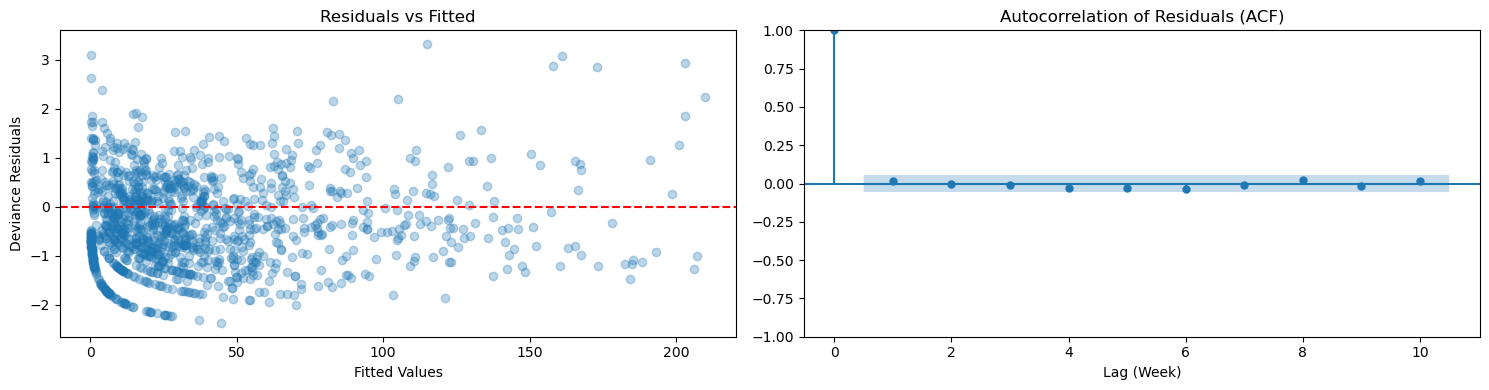

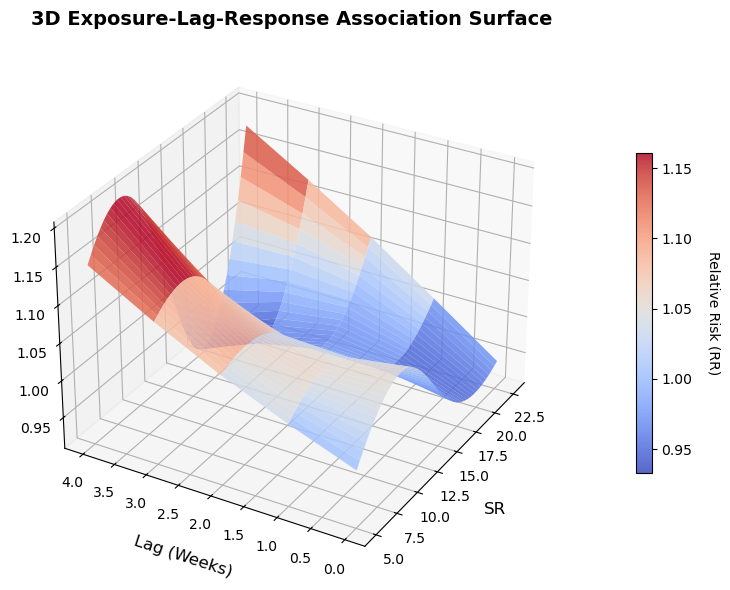

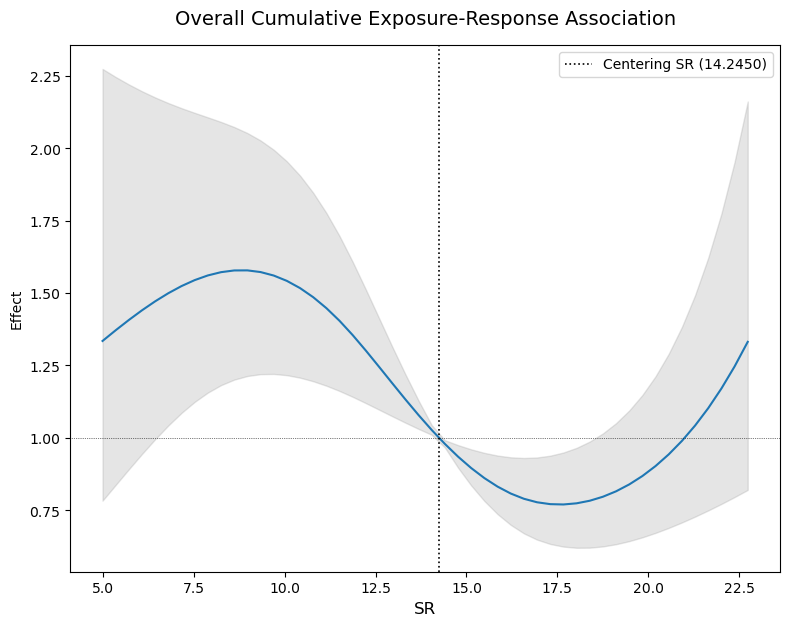

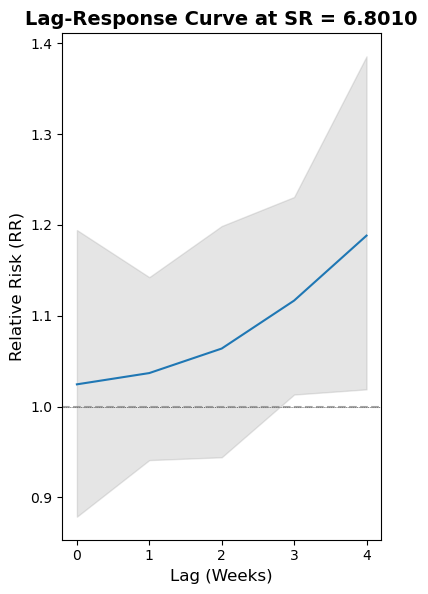

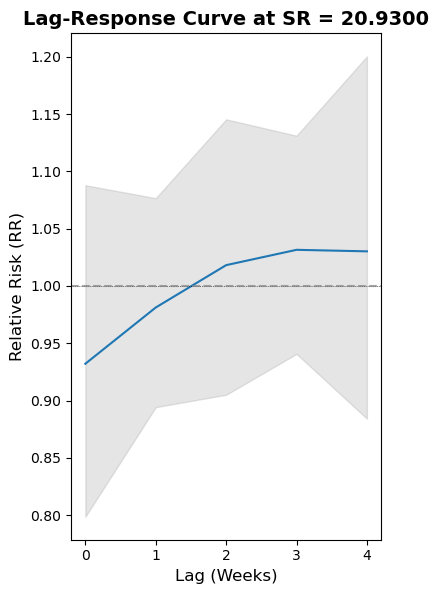

**====================================================================== AP ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10357.82
BIC for (2, 3, 2, 4): 10365.02
BIC for (2, 3, 3, 3): 10357.82
BIC for (2, 3, 3, 4): 10365.02
BIC for (2, 4, 2, 3): 10377.76
BIC for (2, 4, 2, 4): 10388.13
BIC for (2, 4, 3, 3): 10377.76
BIC for (2, 4, 3, 4): 10388.13
BIC for (3, 3, 2, 3): 10357.82
BIC for (3, 3, 2, 4): 10365.02
BIC for (3, 3, 3, 3): 10357.82
BIC for (3, 3, 3, 4): 10365.02
BIC for (3, 4, 2, 3): 10377.76
BIC for (3, 4, 2, 4): 10388.13
BIC for (3, 4, 3, 3): 10377.76
BIC for (3, 4, 3, 4): 10388.13
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10357.82)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10189.9023 | sum(EDF)=28.8279
Degrees of freedom (10, 4, 6): BIC=10189.7644 | sum(EDF)=29.7830
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.716500848916235e-07, 2.7718353248344663e+22...",22185.750636,22185.750636,1.0,0.0
KFold,"(1.0, 5.011872336272722, 25.118864315095795)",9898.691511,10118.036356,1.072221,42.763135



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2131 | BIC = 10118.0364
Dispersion   1.5: Pearson ratio = 0.8406 | BIC = 10222.8788
Dispersion   2.0: Pearson ratio = 0.6461 | BIC = 10388.5333
Dispersion   3.0: Pearson ratio = 0.4442 | BIC = 10731.7935
Dispersion   4.0: Pearson ratio = 0.3396 | BIC = 11043.2324
Dispersion   5.0: Pearson ratio = 0.2755 | BIC = 11318.8918

Best dispersion parameter: 1.5 (Pearson ratio = 0.8406)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1205.18
Model Family:        NegativeBinomial   Df Model:                        41.82
Link Function:                

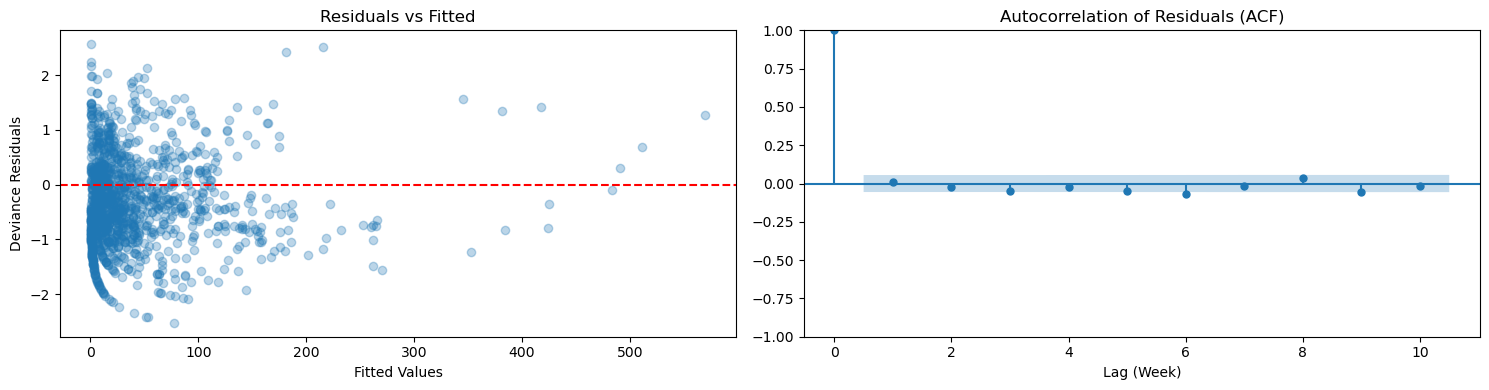

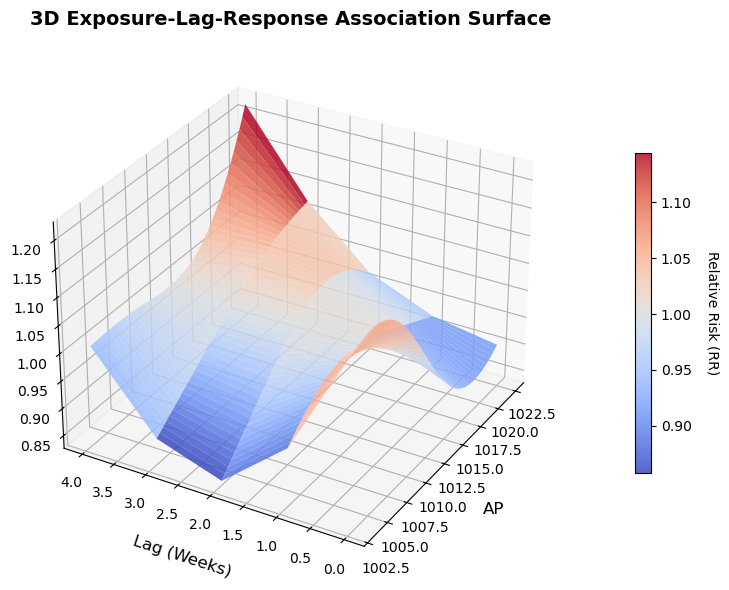

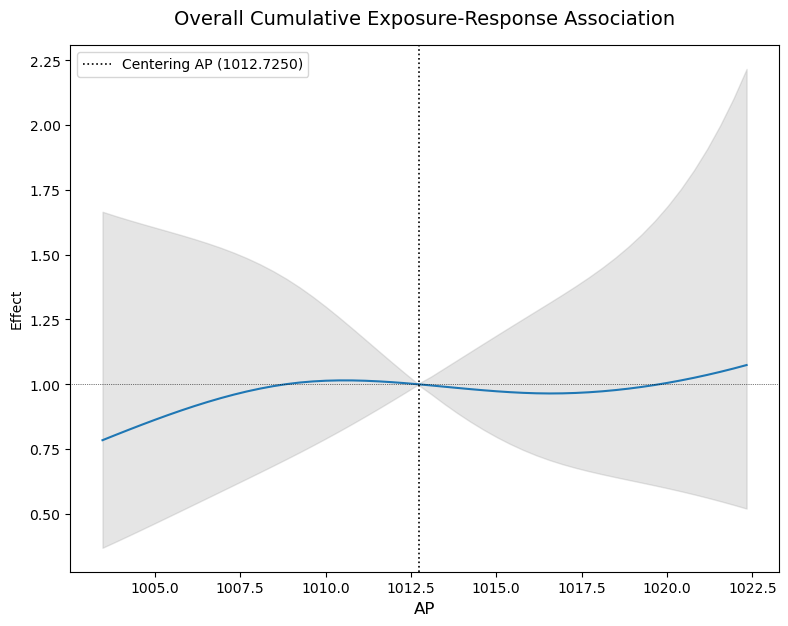

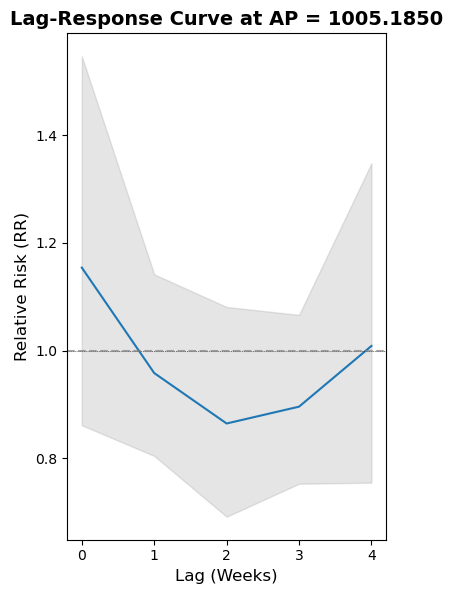

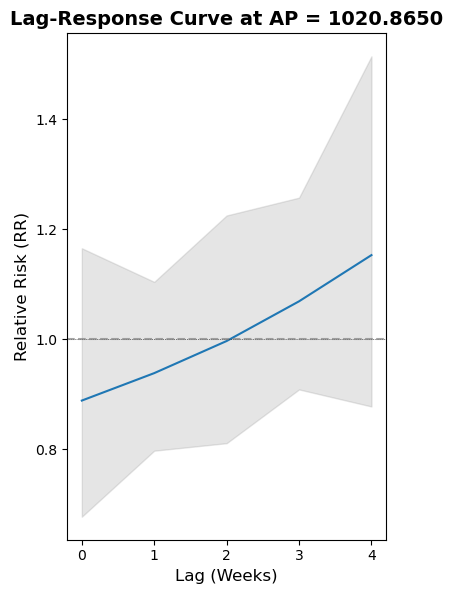

**====================================================================== DPT ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10303.83
BIC for (2, 3, 2, 4): 10308.94
BIC for (2, 3, 3, 3): 10303.83
BIC for (2, 3, 3, 4): 10308.94
BIC for (2, 4, 2, 3): 10320.48
BIC for (2, 4, 2, 4): 10330.67
BIC for (2, 4, 3, 3): 10320.48
BIC for (2, 4, 3, 4): 10330.67
BIC for (3, 3, 2, 3): 10303.83
BIC for (3, 3, 2, 4): 10308.94
BIC for (3, 3, 3, 3): 10303.83
BIC for (3, 3, 3, 4): 10308.94
BIC for (3, 4, 2, 3): 10320.48
BIC for (3, 4, 2, 4): 10330.67
BIC for (3, 4, 3, 3): 10320.48
BIC for (3, 4, 3, 4): 10330.67
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10303.83)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10183.2740 | sum(EDF)=28.1789
Degrees of freedom (10, 4, 6): BIC=10184.5460 | sum(EDF)=29.0493
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.716500848916235e-07, 2.7718353248344663e+22...",22185.750636,22185.750636,1.0,0.0
KFold,"(15848.931924611108, 1.0, 1.0)",9909.771605,10112.435886,1.066458,39.511118



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2137 | BIC = 10112.4359
Dispersion   1.5: Pearson ratio = 0.8447 | BIC = 10210.4438
Dispersion   2.0: Pearson ratio = 0.6519 | BIC = 10371.1492
Dispersion   3.0: Pearson ratio = 0.4513 | BIC = 10707.2638
Dispersion   4.0: Pearson ratio = 0.3452 | BIC = 11015.9888
Dispersion   5.0: Pearson ratio = 0.2808 | BIC = 11288.6189

Best dispersion parameter: 1.5 (Pearson ratio = 0.8447)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1209.03
Model Family:        NegativeBinomial   Df Model:                        37.97
Link Function:                

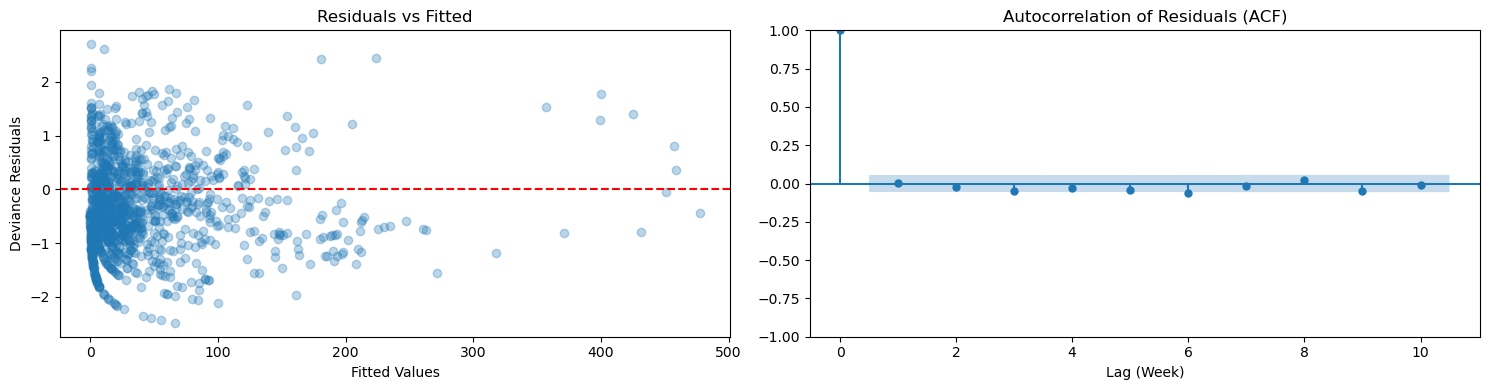

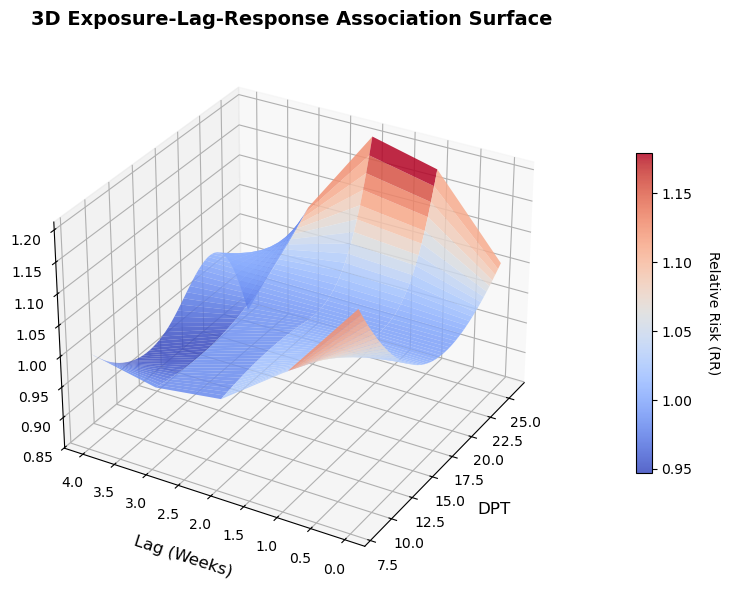

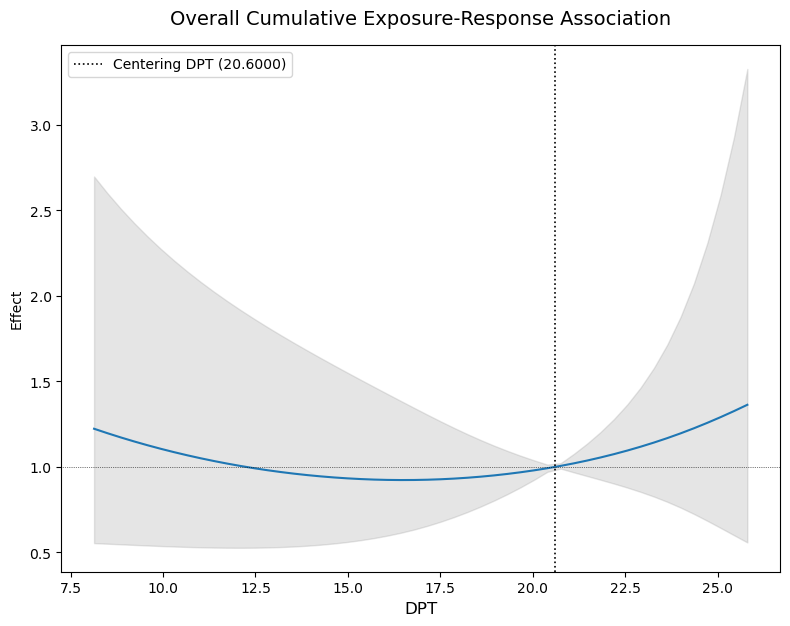

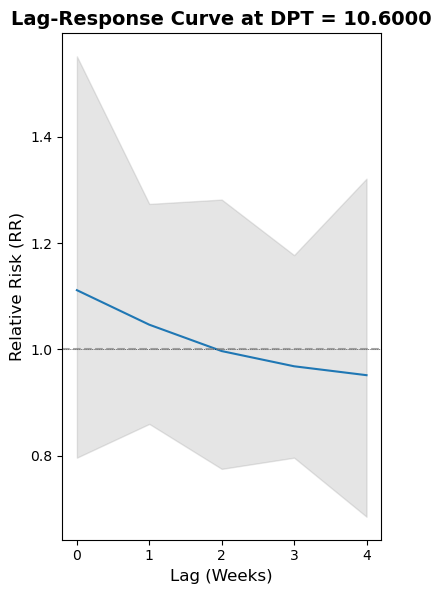

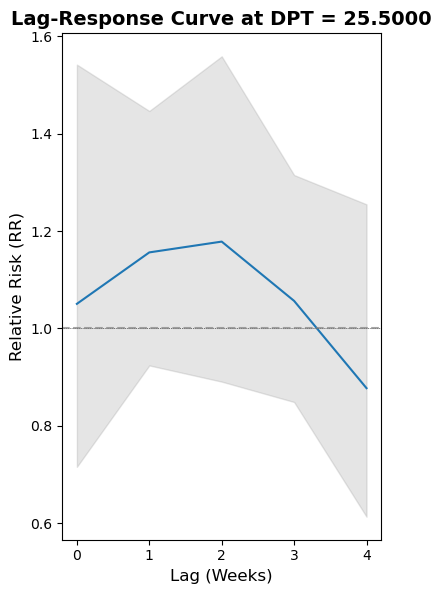

**====================================================================== WS ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10360.32
BIC for (2, 3, 2, 4): 10378.47
BIC for (2, 3, 3, 3): 10360.32
BIC for (2, 3, 3, 4): 10378.47
BIC for (2, 4, 2, 3): 10377.41
BIC for (2, 4, 2, 4): 10402.79
BIC for (2, 4, 3, 3): 10377.41
BIC for (2, 4, 3, 4): 10402.79
BIC for (3, 3, 2, 3): 10360.32
BIC for (3, 3, 2, 4): 10378.47
BIC for (3, 3, 3, 3): 10360.32
BIC for (3, 3, 3, 4): 10378.47
BIC for (3, 4, 2, 3): 10377.41
BIC for (3, 4, 2, 4): 10402.79
BIC for (3, 4, 3, 3): 10377.41
BIC for (3, 4, 3, 4): 10402.79
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10360.32)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10182.9413 | sum(EDF)=28.5718
Degrees of freedom (10, 4, 6): BIC=10182.5971 | sum(EDF)=29.4936
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[1.716500848916235e-07, 2.7718353248344663e+22...",22185.750636,22185.750636,1.0,0.0
KFold,"(15848.931924611108, 630.957344480193, 3162.27...",9927.537957,10125.683346,1.064905,38.630122



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2575 | BIC = 10125.6833
Dispersion   1.5: Pearson ratio = 0.8871 | BIC = 10222.7066
Dispersion   2.0: Pearson ratio = 0.6915 | BIC = 10381.1862
Dispersion   3.0: Pearson ratio = 0.4863 | BIC = 10713.0969
Dispersion   4.0: Pearson ratio = 0.3788 | BIC = 11016.0220
Dispersion   5.0: Pearson ratio = 0.3123 | BIC = 11284.9287

Best dispersion parameter: 1.5 (Pearson ratio = 0.8871)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1210.28
Model Family:        NegativeBinomial   Df Model:                        36.72
Link Function:                

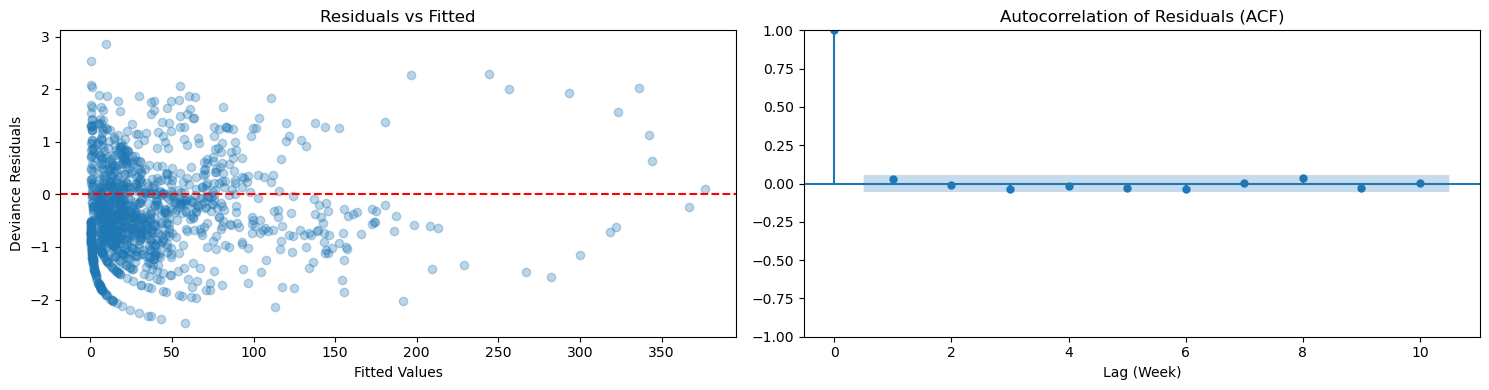

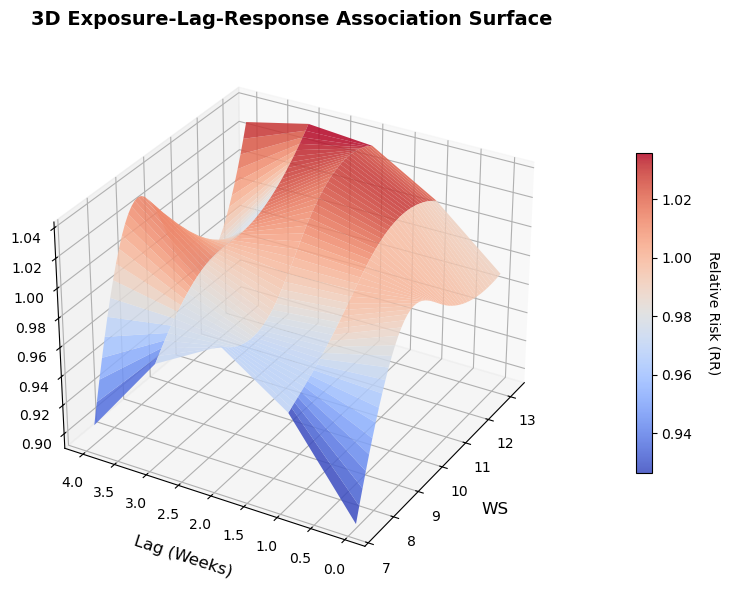

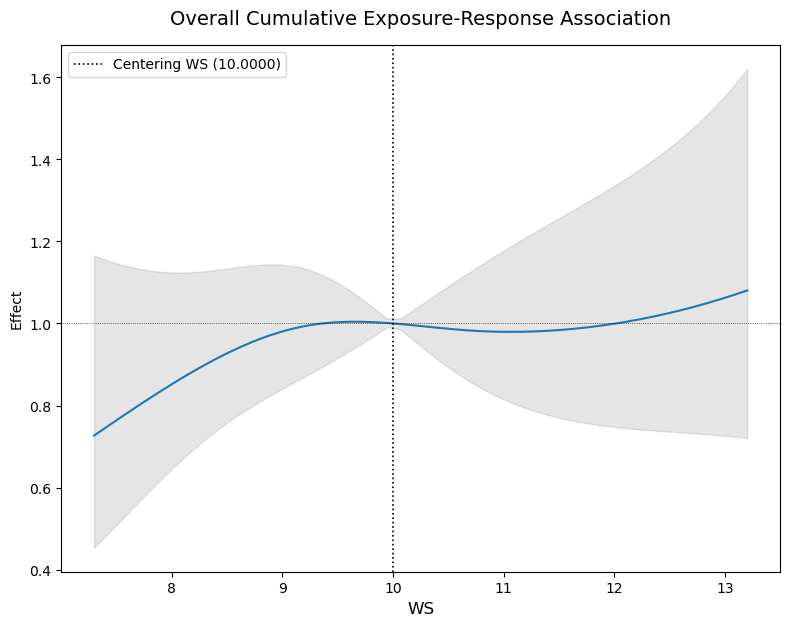

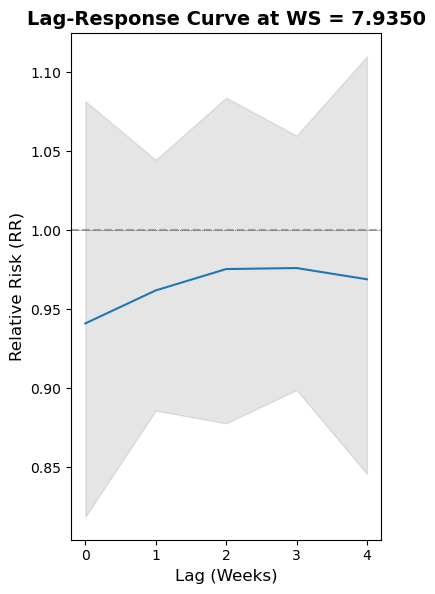

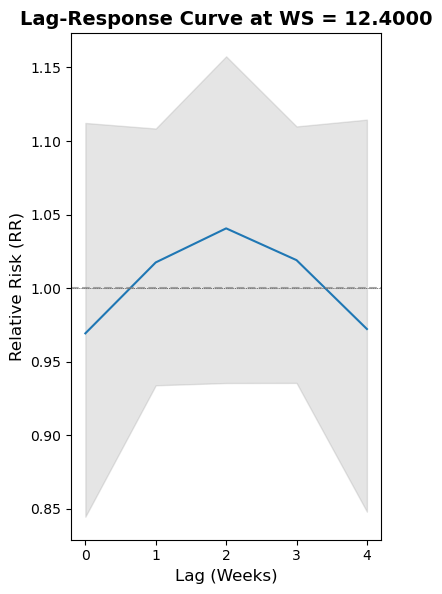

**====================================================================== UV ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10352.75
BIC for (2, 3, 2, 4): 10371.95
BIC for (2, 3, 3, 3): 10352.75
BIC for (2, 3, 3, 4): 10371.95
BIC for (2, 4, 2, 3): 10364.64
BIC for (2, 4, 2, 4): 10390.69
BIC for (2, 4, 3, 3): 10364.64
BIC for (2, 4, 3, 4): 10390.69
BIC for (3, 3, 2, 3): 10352.75
BIC for (3, 3, 2, 4): 10371.95
BIC for (3, 3, 3, 3): 10352.75
BIC for (3, 3, 3, 4): 10371.95
BIC for (3, 4, 2, 3): 10364.64
BIC for (3, 4, 2, 4): 10390.69
BIC for (3, 4, 3, 3): 10364.64
BIC for (3, 4, 3, 4): 10390.69
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10352.75)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (10, 4, 5): BIC=10193.0355 | sum(EDF)=28.5922
Degrees of freedom (10, 4, 6): BIC=10192.0774 | sum(EDF)=29.5008
Degrees 

,alpha,AIC,BIC,GCV,EDF
gcv,"[15.472905893895915, 54.26197425980736, 185.73...",9924.172487,10218.455404,1.098696,57.372947
KFold,"(398107.1705534969, 125.89254117941663, 125.89...",9966.882698,10120.31213,1.049717,29.912367



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.0: Pearson ratio = 1.2584 | BIC = 10120.3121
Dispersion   1.5: Pearson ratio = 0.8905 | BIC = 10214.8820
Dispersion   2.0: Pearson ratio = 0.6941 | BIC = 10360.2334
Dispersion   3.0: Pearson ratio = 0.4881 | BIC = 10694.1503
Dispersion   4.0: Pearson ratio = 0.3794 | BIC = 10995.0092
Dispersion   5.0: Pearson ratio = 0.3115 | BIC = 11256.9977

Best dispersion parameter: 1.5 (Pearson ratio = 0.8905)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      B   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1217.15
Model Family:        NegativeBinomial   Df Model:                        29.85
Link Function:                

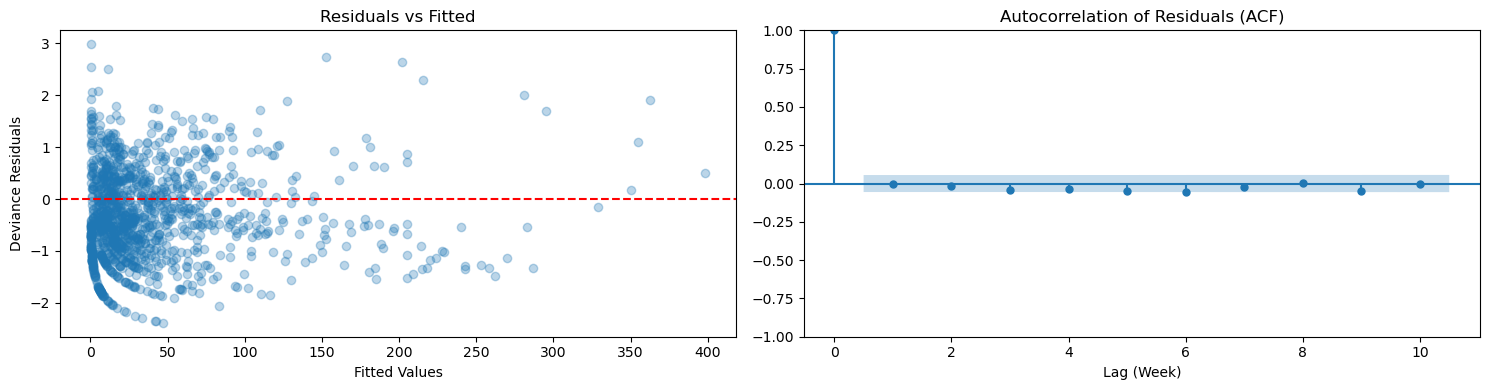

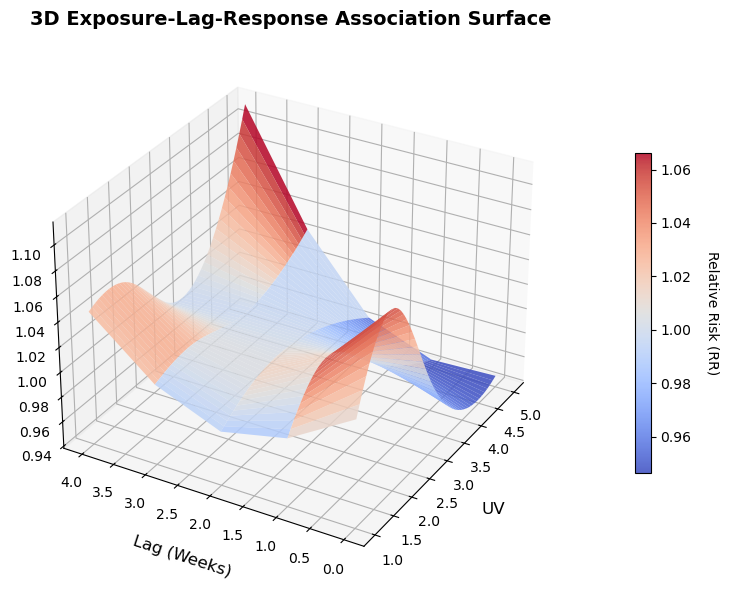

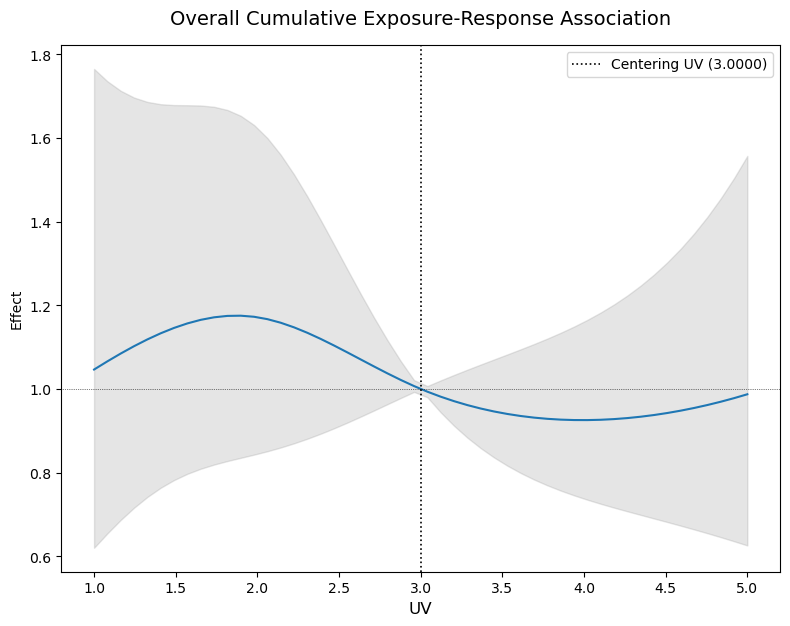

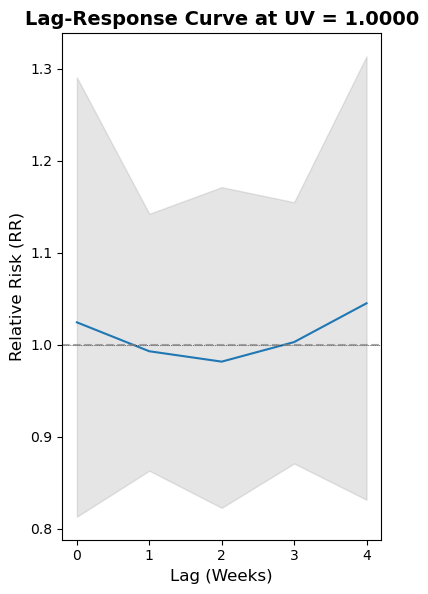

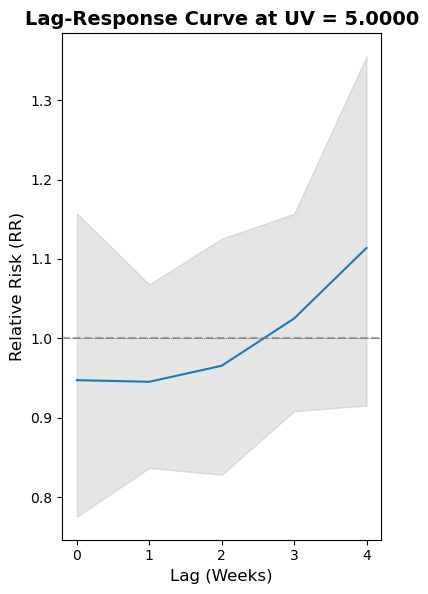

In [23]:
# All meteorological variables for AandB
tar_var = "B"
for exp in mete_col:
    exp_col_list = [exp]

    display(Markdown(f"**{'='*70} {exp} {'='*70}**"))

    pred, model_data, cb_list, nb_result = DLNM_NB(
        df, max_lag=4, 
        tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list,
        bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
        cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=["gcv"]
    )
